# Limpio + Classifier

**Stage 1: RFI multi-label classifier.**
Stage 2 (denoising autoencoder) will follow later.



Este cuaderno arma todo el sistema de deteccion y limpieza de interferencias en las observaciones solares. El flujo general es el siguiente: primero carga senales solares reales y las prepara, rellenando huecos y suavizando. Luego les agrega interferencia sintetica de forma controlada y les pone etiquetas. Con esos datos entrena un clasificador que reconoce que tipo de interferencia hay en cada ventana, y lo evalua. Despues usa las predicciones de ese clasificador para guiar a un autoencoder que reconstruye la senal limpia a partir de la contaminada. Al final aplica un filtrado adicional y compara los resultados. Las explicaciones en espanol que siguen describen, paso a paso, que hace cada celda de codigo, sin modificarla.

## § 1 — Imports and constants

Esta celda carga las librerias que se usan en todo el cuaderno: numpy y pandas para los datos, matplotlib para graficar, scipy para ajustes y estadisticas, y tensorflow con keras para las redes neuronales. Tambien importa el framework de RFI, que es el que genera la interferencia sintetica. Luego define las constantes principales: la ventana completa tiene 300 muestras (5 minutos a 1 Hz) y el clasificador usa solo los primeros 60. Define las cuatro clases del problema: las tres que se pueden inyectar (clock_harmonics, digital_radio y radar) y una cuarta llamada thermal_only, que marca los casos donde no se agrego ninguna interferencia y solo queda el ruido termico. Al final imprime un resumen para confirmar la configuracion.

In [2]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter
from scipy.stats import skew, kurtosis
import math
import warnings
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow.keras.models import Model, Sequential, save_model
from tensorflow.keras.layers import (
    Input, Conv1D, Conv2D, Conv1DTranspose, BatchNormalization, ReLU,
    MaxPooling2D, GlobalAveragePooling1D, GlobalAveragePooling2D,
    Dense, Dropout, Concatenate
)

from keras import layers
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score, multilabel_confusion_matrix,
)

# GPU memory growth
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# RFI framework
#import rfi_framework_v4 as rfi

# ── Window / sampling constants ──────────────────────────────────────
N_FULL       = 300   # full window length (5 min @ 1 Hz)
N_CLASSIFIER = 60    # classifier window length (1 min @ 1 Hz)
SAMPLE_RATE  = 1.0   # Hz

# ── Class definition ────────────────────────────────────────────────
# The first N_RFI_SOURCES classes are the *injectable* RFI types that the
# contamination scenario can add on top of a clean signal.  The last class,
# "thermal_only", is a logical class that is set to 1 whenever no RFI is
# injected (only the always-present thermal noise sits on top of the clean
# signal).  It is mutually exclusive with the three RFI classes BY
# CONSTRUCTION of the labelling logic in `contaminate_dataset`.  The
# classifier outputs N_CLASSES sigmoid probabilities, one per column.
RFI_SOURCES      = ["clock_harmonics", "digital_radio", "radar"]
RFI_CLASSES      = RFI_SOURCES + ["thermal_only"]
N_RFI_SOURCES    = len(RFI_SOURCES)          # = 3 (injectable RFI types)
N_CLASSES        = len(RFI_CLASSES)          # = 4 (total classifier outputs)
THERMAL_ONLY_IDX = N_RFI_SOURCES             # index of the thermal_only column = 3

print(f"TensorFlow {tf.__version__}")
print(f"GPUs: {gpus}")
print(f"Full window:       {N_FULL} samples  ({N_FULL/SAMPLE_RATE/60:.0f} min)")
print(f"Classifier window: {N_CLASSIFIER} samples  ({N_CLASSIFIER/SAMPLE_RATE/60:.0f} min, "
      f"first slice)")
print(f"Injectable RFI sources: {RFI_SOURCES}")
print(f"All classifier classes: {RFI_CLASSES}")
print(f"thermal_only column index: {THERMAL_ONLY_IDX}")


TensorFlow 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Full window:       300 samples  (5 min)
Classifier window: 60 samples  (1 min, first slice)
Injectable RFI sources: ['clock_harmonics', 'digital_radio', 'radar']
All classifier classes: ['clock_harmonics', 'digital_radio', 'radar', 'thermal_only']
thermal_only column index: 3


## § 2 — Data loading (real clean windows)

In [3]:
x = np.loadtxt('Clean_signals.csv', delimiter=',')

## § 4 — Kalman filter (kept for future use)

Define un filtro de Kalman sencillo en una dimension. Es un filtro que suaviza una senal estimando, muestra a muestra, el valor mas probable a partir del valor anterior y de la nueva medicion. El parametro Q controla cuanto se confia en que la senal cambia poco, y R cuanto ruido se asume en la medicion. Devuelve la senal filtrada, los residuos (la diferencia con la original) y la ganancia de Kalman en cada paso. Por ahora la funcion solo se define.

In [4]:
def kalman_filter_1d(signal, Q=1e-5, R=1e-2, x0=None, P0=1.0):
    """Simple 1D Kalman Filter for signal denoising."""
    signal = np.asarray(signal)
    n = len(signal)
    filtered_signal = np.zeros(n)
    P = np.zeros(n)
    K_values = np.zeros(n)
    filtered_signal[0] = signal[0] if x0 is None else x0
    P[0] = P0
    for k in range(1, n):
        x_pred = filtered_signal[k - 1]
        P_pred = P[k - 1] + Q
        K = P_pred / (P_pred + R)
        filtered_signal[k] = x_pred + K * (signal[k] - x_pred)
        P[k] = (1 - K) * P_pred
        K_values[k] = K
    residuals = signal - filtered_signal
    return filtered_signal, residuals, K_values

Esta celda aplica el filtro de Kalman anterior a cada ventana de x, una por una, y reemplaza cada ventana por su version suavizada.

In [5]:
samples= len(x)
points=300
t = np.linspace(0, 300, points)
for i in range(len(x)):
    x[i], residuals, K_values = kalman_filter_1d(x[i], Q=1e-5, R=1e-2, x0=None, P0=1.0)

## RFI contamination on the full 300-sample windows


Se recarga el data set con interferencia y limpio

In [6]:
_loaded = np.load("rfi_dataset.npz")
ds = {k: _loaded[k] for k in _loaded.files}
print({k: (v.shape, str(v.dtype)) for k, v in ds.items()})

{'clean': ((50000, 300), 'float32'), 'contaminated': ((50000, 300), 'float32'), 'labels': ((50000, 4), 'int8'), 'sir_db': ((50000,), 'float32')}


## Slice to first 60 samples for the classifier



El clasificador no usa la ventana completa de 300 muestras, sino solo los primeros 60. Esta celda corta tanto las senales contaminadas como las limpias a esos 60 valores iniciales, deja las etiquetas igual (son por ventana) y comprueba que las formas sean las esperadas.

In [7]:
N_DATA = 50000
def slice_for_classifier(signals_300: np.ndarray,
                         n_samples: int = N_CLASSIFIER) -> np.ndarray:
    """Slice (N, 300) → (N, 60). Asserts shape correctness."""
    assert signals_300.ndim == 2, f"Expected 2D, got {signals_300.shape}"
    assert signals_300.shape[1] >= n_samples, \
        f"Cannot take {n_samples} from window of {signals_300.shape[1]}"
    return signals_300[:, :n_samples]

# Slice contaminated signals for classifier input
sig_60       = slice_for_classifier(ds['contaminated'])
clean_60     = slice_for_classifier(ds['clean'])           # kept for comparison
labels       = ds['labels']                                 # unchanged (window-level)

# Shape validation
assert sig_60.shape == (N_DATA, N_CLASSIFIER)
assert clean_60.shape == (N_DATA, N_CLASSIFIER)
assert labels.shape == (N_DATA, N_CLASSES)
print(f"sig_60:    {sig_60.shape}  (classifier input)")
print(f"clean_60:  {clean_60.shape}")
print(f"labels:    {labels.shape}")

sig_60:    (50000, 60)  (classifier input)
clean_60:  (50000, 60)
labels:    (50000, 4)


## Input

1. CWT scalogram (32, 60) for the 2D CNN
2. Raw normalized signal (60, 1) for the 1D CNN


Aqui se definen tres maneras de representar cada senal de 60 muestras para alimentar al modelo. La primera la transformada wavelet continua de Morlet, que muestra la energia de la senal en distintas escalas de tiempo y queda como una imagen de 32 por 60. La segunda es la senal cruda normalizada: a cada ventana se le resta su media y se divide por su desviacion.

In [8]:
# ── 7a. CWT scalogram (Morlet, reflection padding) ──

def _morlet(M, s, w=5.0):
    xs = (np.arange(M) - (M - 1) / 2) / s
    return np.exp(1j*w*xs) * np.exp(-0.5*xs*xs) * (np.pi**-0.25)

def _cwt(data, widths, w=5.0):
    n = len(data)
    out = np.empty((len(widths), n), dtype=np.complex128)
    for i, s in enumerate(widths):
        M = min(int(10 * s + 1) | 1, n)
        wav = _morlet(M, s, w)
        out[i] = np.convolve(data, np.conj(wav[::-1]), mode="same")
    return out

CWT_SCALES = 32

def make_scalogram(sig: np.ndarray, n_scales: int = CWT_SCALES, pad: int = 20):
    """(60,) → (n_scales, 60) float32 log-normalised to [0,1]."""
    n = len(sig)
    padded = np.pad(sig, pad, mode="reflect")
    widths = np.geomspace(1, n // 2, num=n_scales)
    coefs = _cwt(padded, widths)
    mag = np.abs(coefs[:, pad:pad+n]).astype(np.float32)
    mag = np.log1p(mag)
    lo, hi = mag.min(), mag.max()
    if hi - lo > 1e-8:
        mag = (mag - lo) / (hi - lo)
    return mag

def batch_scalograms(signals: np.ndarray):
    """(N, 60) → (N, CWT_SCALES, 60, 1) float32."""
    N = len(signals)
    first = make_scalogram(signals[0])
    H, W = first.shape
    out = np.empty((N, H, W, 1), dtype=np.float32)
    out[0, :, :, 0] = first
    for i in range(1, N):
        out[i, :, :, 0] = make_scalogram(signals[i])
    return out


# ── 7b. Raw 1D (per-sample z-normalised) ──

def prepare_1d(signals: np.ndarray):
    """(N, 60) → (N, 60, 1) float32 z-normalised per sample."""
    arr = signals.astype(np.float32)
    mu = arr.mean(axis=1, keepdims=True)
    sd = arr.std(axis=1, keepdims=True) + 1e-8
    arr = (arr - mu) / sd
    return arr[:, :, np.newaxis]


# ── 7c. Statistical features ──

def extract_features(sig: np.ndarray):
    """(60,) → (21,) float32."""
    z = sig - np.mean(sig)
    rms = np.sqrt(np.mean(z**2)) + 1e-30
    f = [np.mean(sig), np.std(sig), float(skew(sig)), float(kurtosis(sig)),
         np.max(sig), np.min(sig), np.max(np.abs(z))/rms,
         np.sum(np.diff(np.sign(z)) != 0)/len(z)]
    acf = np.correlate(z, z, "full")[len(z)-1:]
    acf = acf / (acf[0] + 1e-30)
    for lag in [1, 2, 3, 5, 10]:
        f.append(acf[lag] if lag < len(acf) else 0.0)
    fft_mag = np.abs(np.fft.rfft(z))[:len(z)//2]
    bins = 8
    bs = max(len(fft_mag)//bins, 1)
    for b in range(bins):
        s_, e_ = b*bs, min((b+1)*bs, len(fft_mag))
        f.append(float(np.mean(fft_mag[s_:e_]**2)) if e_ > s_ else 0.0)
    return np.array(f, dtype=np.float32)

def batch_features(signals: np.ndarray):
    """(N, 60) → (N, 21) float32."""
    return np.array([extract_features(s) for s in signals])

### Shape validation

Una comprobacion rapida: genera las tres representaciones para cinco senales de ejemplo y verifica que cada una tenga la forma correcta. Sirve para detectar errores de dimensiones antes de entrenar.

In [9]:
def validate_shapes():
    X_scal = batch_scalograms(sig_60[:5])
    X_1d   = prepare_1d(sig_60[:5])
    X_feat = batch_features(sig_60[:5])

    checks = [
        (X_scal.shape, (5, CWT_SCALES, N_CLASSIFIER, 1), "scalogram"),
        (X_1d.shape,   (5, N_CLASSIFIER, 1),              "raw 1D"),
        (X_feat.shape, (5, 21),                            "features"),
        (labels.shape, (N_DATA, N_CLASSES),                "labels"),
    ]
    for actual, expected, name in checks:
        ok = "✓" if actual == expected else "✗"
        print(f"  {ok} {name:12s}  {actual}  (expected {expected})")

validate_shapes()

  ✓ scalogram     (5, 32, 60, 1)  (expected (5, 32, 60, 1))
  ✓ raw 1D        (5, 60, 1)  (expected (5, 60, 1))
  ✓ features      (5, 21)  (expected (5, 21))
  ✓ labels        (50000, 4)  (expected (50000, 4))


## Train / validation / test split

80% train, 10% validation, 10% test from the contaminated dataset.

Esta celda separa los datos en tres grupos: entrenamiento, validacion y prueba. Reserva un quinto para prueba y otro quinto para validacion, y el resto para entrenar. Guarda aparte las versiones completas de 300 muestras del grupo de prueba, que se usaran mas adelante con el autoencoder.

In [10]:
rng = np.random.default_rng(0)
perm = rng.permutation(N_DATA)
n_test  = N_DATA // 5
n_val   = N_DATA // 5
i_test  = perm[:n_test]
i_val   = perm[n_test:n_test+n_val]
i_train = perm[n_test+n_val:]

sig_train, lab_train = sig_60[i_train], labels[i_train]
sig_val,   lab_val   = sig_60[i_val],   labels[i_val]
sig_test,  lab_test  = sig_60[i_test],  labels[i_test]

# also keep the full 300-sample versions of the test set for the
# future autoencoder
full_test  = ds['contaminated'][i_test]
clean_test = ds['clean'][i_test]

# No augmentation: alias the *_aug names to the original training set so the
# downstream training cells (§11) keep working without any change.
sig_train_aug, lab_train_aug = sig_train, lab_train

print(f"Train: {sig_train.shape}  labels: {lab_train.shape}")
print(f"Val:   {sig_val.shape}  labels: {lab_val.shape}")
print(f"Test:  {sig_test.shape}  labels: {lab_test.shape}")
print(f"Test (full 300): {full_test.shape}  (kept for future autoencoder)")

Train: (30000, 60)  labels: (30000, 4)
Val:   (10000, 60)  labels: (10000, 4)
Test:  (10000, 60)  labels: (10000, 4)
Test (full 300): (10000, 300)  (kept for future autoencoder)


## Classifier architectures




Aqui se definen las redes. build_2d_cnn es una red convolucional 2D que trabaja sobre la trasnformada Wavelet. build_1d_cnn es el modelo principal: tiene dos entradas, la senal cruda y la Wavelet, las procesa por ramas separadas y luego une las dos ramas antes de la capa final. build_1d_cnn1 es una red 1D mas simple que solo usa la senal cruda. Todas terminan en cuatro salidas con activacion sigmoide, una probabilidad por clase, porque una ventana puede tener varias clases a la vez. La funcion compile_and_train arma el modelo con la perdida de entropia cruzada binaria y el optimizador Adam, y lo entrena con parada temprana y reduccion de la tasa de aprendizaje cuando deja de mejorar.

In [11]:
def build_2d_cnn(input_shape=(CWT_SCALES, N_CLASSIFIER, 1),
                  n_classes=N_CLASSES):
    """2D CNN on CWT scalogram.  ~27K parameters."""
    inp = Input(shape=input_shape, name="scalogram")
    x = inp
    for f in [10, 10, 10]:
        x = Conv2D(f, 3, padding="same")(x)
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = MaxPooling2D(2)(x)
    x = GlobalAveragePooling2D()(x)
    x = Dense(48, activation="relu")(x)
    x = Dropout(0.2)(x)
    out = Dense(n_classes, activation="sigmoid",  name="output")(x)
    return Model(inp, out, name="cnn_2d_scalogram")


def build_1d_cnn(input_shape=(N_CLASSIFIER, 1), input_shape2=(CWT_SCALES, N_CLASSIFIER, 1), n_classes=N_CLASSES):
    """1D CNN on raw signal with dilated convolutions.  ~15K parameters.

    Dilations 1, 2, 4 with kernel 5 give a receptive field of 29 samples;
    after global average pooling, the network "sees" the full 60-sample
    window.
    """
    inp = Input(shape=input_shape, name="raw_signal")
    x = inp
    for f, k, d,  s in [(32, 9, 1, 2), (32, 9, 1, 1), (64, 5, 4, 1),(128, 5, 4, 1), (128, 5, 4, 1)]:
        x = Conv1D(f, k, dilation_rate=d,  strides=s,  padding="same")(x)
        x = BatchNormalization()(x)
        x = ReLU()(x)
    x = GlobalAveragePooling1D()(x)
    #x = Dense(32, activation="relu")(x)
    #x = Dropout(0.3)(x)

    sp_in = Input(shape=input_shape2, name="scalogram")
    y= sp_in
    y = Conv2D(32, (3,3 ), padding="same", activation="relu", kernel_initializer="he_normal")(y)
    y = MaxPooling2D((2,2 ))(y)
    y = Conv2D(32, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal")(y)
    y = Conv2D(64, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal")(y)
    y = Conv2D(32, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal")(y)
    y = MaxPooling2D((2, 2))(y)
    y = Conv2D(64, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal")(y)
    y = Conv2D(64, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal")(y)
    y = Conv2D(128, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal")(y)
    y = GlobalAveragePooling2D(name="sp_pool")(y)

    h = Concatenate(name="fusion")([x, y])
    h = Dense(128, activation="relu")(h)
    h = Dropout(0.5)(h)
    h = Dense(128, activation="relu")(h)
    h = Dropout(0.2)(h)



    out = Dense(n_classes, activation="sigmoid", name="output")(h)
    return Model(inputs=[inp, sp_in], outputs=out, name="cnn_1x2d_raw")

def build_1d_cnn1(input_shape=(N_CLASSIFIER, 1), n_classes=N_CLASSES):
    """1D CNN on raw signal with dilated convolutions.  ~15K parameters.

    Dilations 1, 2, 4 with kernel 5 give a receptive field of 29 samples;
    after global average pooling, the network "sees" the full 60-sample
    window.
    """
    inp = Input(shape=input_shape, name="raw_signal")
    x = inp
    for f, k, d in [(10, 3, 4), (10, 3, 1), (10, 3, 4),(10, 3, 4),(10, 3, 4),(10, 3, 4)]:
        x = Conv1D(f, k, dilation_rate=d, padding="same")(x)
        x = BatchNormalization()(x)
        x = ReLU()(x)
    x = GlobalAveragePooling1D()(x)
    x = Dense(32, activation="relu")(x)
    x = Dropout(0.2)(x)
    out = Dense(n_classes, activation="sigmoid", name="output")(x)
    return Model(inp, out, name="cnn_1d_raw")

def compile_and_train(model, X_trn, y_trn, X_val, y_val,
                       epochs=40, batch_size=64):
    """Compile with BCE + Adam and train with early stopping."""
    model.compile(
        optimizer=Adam(1e-3),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="acc"),
            tf.keras.metrics.AUC(name="auc", multi_label=True),
        ],
        jit_compile=False,
    )
    history = model.fit(
        X_trn, y_trn,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=batch_size, verbose=2,
        callbacks=[
            EarlyStopping(monitor="val_auc", patience=30, mode="max",
                          restore_best_weights=True, verbose=1),
            ReduceLROnPlateau(monitor="val_auc", factor=0.5, patience=8,
                              min_lr=1e-6, verbose=1),
        ],
    )
    return history

## § 11 — Train all three models

Antes de entrenar, esta celda calcula de antemano las representaciones (Wavelet y senal cruda) para los conjuntos de entrenamiento, validacion y prueba, y las caracteristicas para el random forest. Tambien convierte las etiquetas a float32.

In [12]:
# Prepare representations
print("Preparing representations …")
print("Preparing X2d_trn …")
X2d_trn = batch_scalograms(sig_train_aug)
print("Preparing X2d_val …")
X2d_val = batch_scalograms(sig_val)
print("Preparing X2d_tst …")
X2d_tst = batch_scalograms(sig_test)
print("Preparing X1d_trn …")
X1d_trn = prepare_1d(sig_train_aug)
print("Preparing X1d_val …")
X1d_val = prepare_1d(sig_val)
print("Preparing X1d_tst …")
X1d_tst = prepare_1d(sig_test)
Xf_trn  = batch_features(sig_train)
Xf_tst  = batch_features(sig_test)


y_trn = lab_train_aug.astype(np.float32)
y_val = lab_val.astype(np.float32)
y_tst = lab_test.astype(np.float32)

Preparing representations …
Preparing X2d_trn …
Preparing X2d_val …
Preparing X2d_tst …
Preparing X1d_trn …
Preparing X1d_val …
Preparing X1d_tst …


Entrena el modelo principal, la red que combina senal cruda y escalograma. Imprime el numero de parametros y guarda el historial de entrenamiento.

In [13]:
# ── 2D+1D CNN ──
print("\n══ Training 2D +1D CNN (raw signal) ══")
m1d = build_1d_cnn()
print(f"Parameters: {m1d.count_params():,}")
h1d = compile_and_train(m1d, (X1d_trn, X2d_trn), y_trn, (X1d_val, X2d_val), y_val,
                         epochs=2, batch_size=90)



══ Training 2D +1D CNN (raw signal) ══


I0000 00:00:1782738552.798325   80531 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9507 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4080 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Parameters: 370,276
Epoch 1/2


I0000 00:00:1782738559.643439   81024 cuda_dnn.cc:461] Loaded cuDNN version 90300


334/334 - 20s - 59ms/step - acc: 0.8882 - auc: 0.9508 - loss: 0.2513 - val_acc: 0.8828 - val_auc: 0.9651 - val_loss: 0.2552 - learning_rate: 0.0010
Epoch 2/2
334/334 - 8s - 23ms/step - acc: 0.9268 - auc: 0.9714 - loss: 0.1760 - val_acc: 0.9370 - val_auc: 0.9791 - val_loss: 0.1467 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 2.


##  Evaluation

Define funciones para evaluar los modelos sobre el conjunto de prueba. Para cada modelo imprime un reporte con precision, exhaustividad y F1 por clase, y el AUC de cada clase. Luego evalua la red 2D, la red combinada, la red 1D y el random forest.

In [14]:
def evaluate_cnn(model, X_test, y_test, name, threshold=0.5):
    y_prob = model.predict(X_test, verbose=0)
    y_pred = (y_prob >= threshold).astype(int)
    print(f"\n{'═'*15}  {name}  {'═'*15}")
    print(classification_report(y_test, y_pred,
                                 target_names=RFI_CLASSES, zero_division=0))
    for i, n in enumerate(RFI_CLASSES):
        if y_test[:, i].sum() > 0:
            auc = roc_auc_score(y_test[:, i], y_prob[:, i])
            print(f"  AUC {n:18s}  {auc:.3f}")
    return y_prob, y_pred

def evaluate_rf(clf, X_test, y_test):
    y_pred = clf.predict(X_test)
    print(f"\n{'═'*15}  Random Forest  {'═'*15}")
    print(classification_report(y_test, y_pred,
                                 target_names=RFI_CLASSES, zero_division=0))
    return y_pred

prob_1d, pred_1d = evaluate_cnn(m1d, (X1d_tst, X2d_tst), y_tst, "2D 1D CNN (raw)")
#m1d.save("Classifier.keras")


═══════════════  2D 1D CNN (raw)  ═══════════════
                 precision    recall  f1-score   support

clock_harmonics       0.99      0.94      0.96      5013
  digital_radio       0.98      0.92      0.95      4984
          radar       0.95      0.75      0.84      4998
   thermal_only       0.93      1.00      0.96      2475

      micro avg       0.97      0.89      0.93     17470
      macro avg       0.96      0.90      0.93     17470
   weighted avg       0.97      0.89      0.92     17470
    samples avg       0.97      0.91      0.93     17470

  AUC clock_harmonics     0.994
  AUC digital_radio       0.992
  AUC radar               0.934
  AUC thermal_only        0.992


## Visualisation

Training curves and confusion matrices for the two CNNs.

Define dos graficos. plot_history dibuja la perdida y el AUC de validacion a lo largo de las epocas. plot_confusion dibuja una matriz de confusion por clase. Al final se muestran las curvas de entrenamiento y las matrices de la red 2D y la combinada.

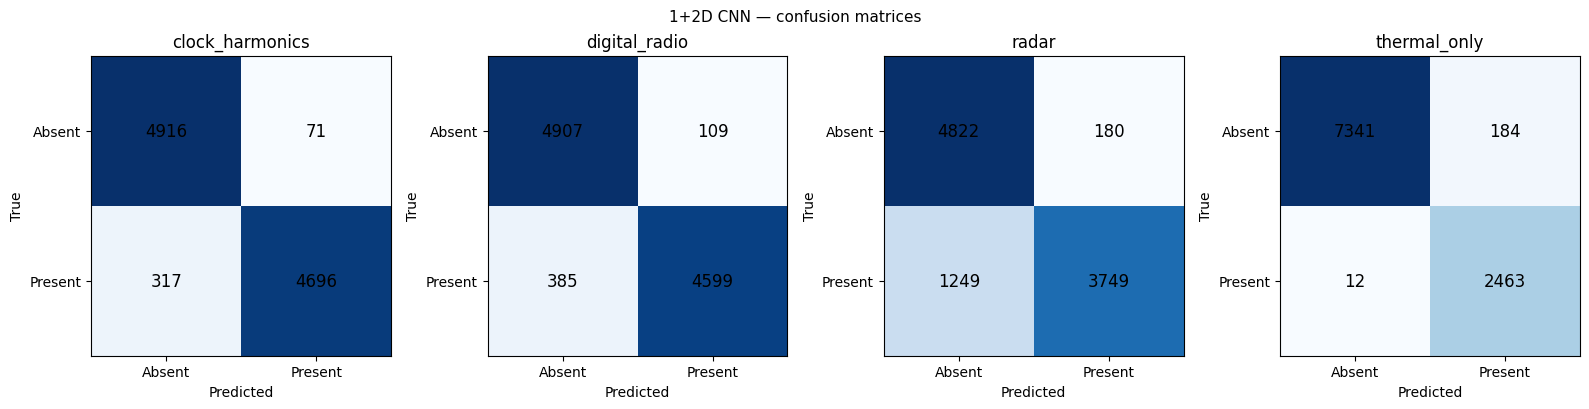

In [15]:
def plot_history(hists: dict):
    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
    for label, h in hists.items():
        a.plot(h.history["val_loss"], label=label)
        b.plot(h.history["val_auc"], label=label)
    a.set(xlabel="Epoch", ylabel="Val loss", title="Validation Loss")
    b.set(xlabel="Epoch", ylabel="Val AUC",  title="Validation AUC")
    a.legend(); b.legend()
    plt.tight_layout()
    return fig

def plot_confusion(y_true, y_pred, title=""):
    mcm = multilabel_confusion_matrix(y_true, y_pred)
    fig, axes = plt.subplots(1, N_CLASSES, figsize=(4*N_CLASSES, 4))
    fig.suptitle(title, fontsize=11)
    for ax, cm, name in zip(axes, mcm, RFI_CLASSES):
        ax.imshow(cm, cmap="Blues")
        for (r, c), v in np.ndenumerate(cm):
            ax.text(c, r, str(v), ha="center", va="center", fontsize=12)
        ax.set(xticks=[0, 1], yticks=[0, 1],
               xticklabels=["Absent", "Present"],
               yticklabels=["Absent", "Present"],
               xlabel="Predicted", ylabel="True", title=name)
    plt.tight_layout()
    return fig



plot_confusion(y_tst, pred_1d, "1+2D CNN — confusion matrices")
plt.show()

## Ejemplo



Muestra un ejemplo. Para una ventana dada, grafica arriba la ventana completa de 300 muestras con la parte que ve el clasificador resaltada, y abajo las probabilidades que da el modelo para cada clase, junto con la etiqueta verdadera. Se muestran dos casos: una ventana con interferencia y una ventana solo termica.

── RFI-contaminated window ──


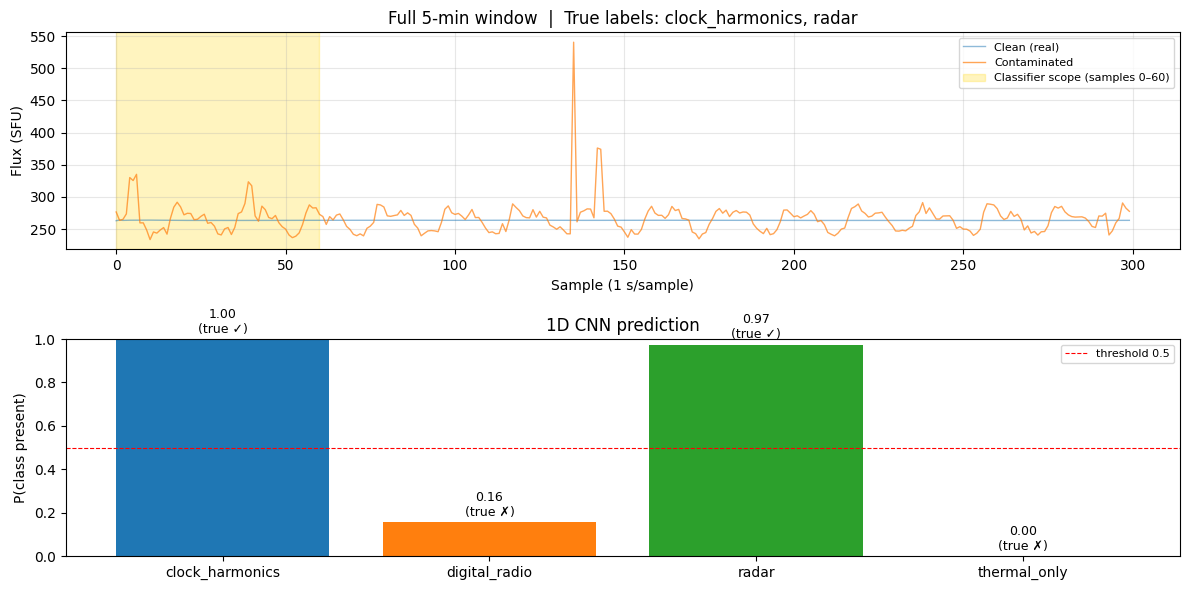


── thermal_only window (no RFI present) ──


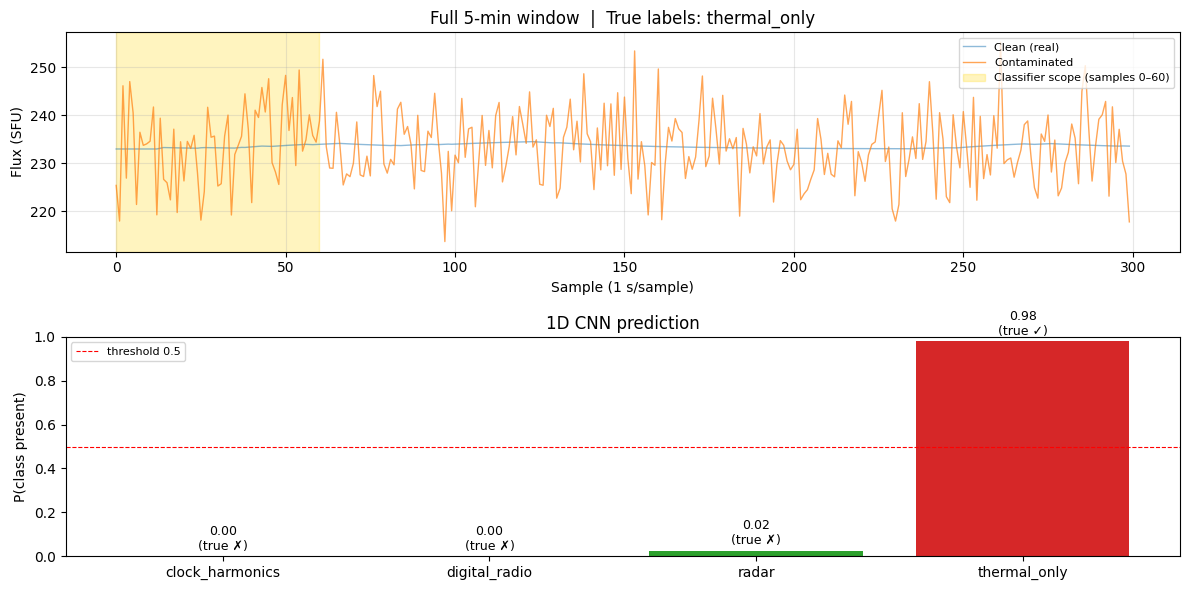

In [16]:
def inference_example(model, X_test, full_test, clean_test, y_test, idx=0,
                       name="Model"):
    # Support both single-input and tuple-input models (the 1D CNN uses
    # raw + scalogram as a two-headed input).
    if isinstance(X_test, tuple):
        Xb = tuple(t[idx:idx+1] for t in X_test)
    else:
        Xb = X_test[idx:idx+1]
    prob = model.predict(Xb, verbose=0)[0]
    true_labels = [RFI_CLASSES[j] for j in range(N_CLASSES) if y_test[idx, j]]

    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=False)

    # Top: full 300-sample window with the first-60 slice highlighted
    t300 = np.arange(N_FULL)
    axes[0].plot(t300, clean_test[idx], lw=1.0, alpha=0.5, label="Clean (real)")
    axes[0].plot(t300, full_test[idx],  lw=1.0, alpha=0.7, label="Contaminated")
    axes[0].axvspan(0, N_CLASSIFIER, color="gold", alpha=0.25,
                    label=f"Classifier scope (samples 0–{N_CLASSIFIER})")
    axes[0].set(xlabel="Sample (1 s/sample)", ylabel="Flux (SFU)",
                title=f"Full 5-min window  |  True labels: {', '.join(true_labels) or 'none'}")
    axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

    # Bottom: bar chart of prediction probabilities — one colour per class
    # (auto-sized to N_CLASSES so the figure adapts if classes change)
    colors = [f"C{i}" for i in range(N_CLASSES)]
    axes[1].bar(RFI_CLASSES, prob, color=colors)
    axes[1].axhline(0.5, color='r', ls='--', lw=0.8, label='threshold 0.5')
    axes[1].set(ylim=(0, 1), ylabel="P(class present)",
                title=f"{name} prediction")
    # Annotate values + ground truth
    for i, (n, p) in enumerate(zip(RFI_CLASSES, prob)):
        truth = "✓" if y_test[idx, i] else "✗"
        axes[1].text(i, p + 0.03, f"{p:.2f}\n(true {truth})",
                     ha="center", fontsize=9)
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    return fig

# ── Two example windows: one RFI-contaminated, one thermal-only ──
rfi_mask     = y_tst[:, :N_RFI_SOURCES].sum(axis=1) > 0
thermal_mask = y_tst[:, THERMAL_ONLY_IDX] == 1

idx_rfi     = int(np.where(rfi_mask)[0][0])
idx_thermal = int(np.where(thermal_mask)[0][0])

print("── RFI-contaminated window ──")
inference_example(m1d, (X1d_tst, X2d_tst), full_test, clean_test, y_tst,
                   idx=idx_rfi, name="1D CNN")
plt.show()

print("\n── thermal_only window (no RFI present) ──")
inference_example(m1d, (X1d_tst, X2d_tst), full_test, clean_test, y_tst,
                   idx=idx_thermal, name="1D CNN")
plt.show()


## Autoencoder interface

Prepara la conexion con el autoencoder. La funcion classify_and_pair toma ventanas completas de 300 muestras, clasifica usando los primeros 60 y devuelve tanto las probabilidades del clasificador como la ventana completa sin cambios. El autoencoder usara esas probabilidades como informacion de contexto para saber que tipo de interferencia debe limpiar.

In [18]:
def classify_and_pair(contaminated_300: np.ndarray,
                      model,
                      representation: str = "1d") -> tuple[np.ndarray, np.ndarray]:
    """
    Take full 300-sample contaminated windows, classify (using first 60),
    and return both the prediction and the full window. This is the
    interface the autoencoder consumes.

    Parameters
    ----------
    contaminated_300 : (N, 300) float
    model            : trained Keras model
    representation   : "1d" → raw 1D + scalogram (fused 1D CNN model)
                       "2d" → scalogram only (2D CNN model)

    Returns
    -------
    predictions : (N, N_CLASSES) float
        Sigmoid probabilities, one column per class.
        Column indices 0 … N_RFI_SOURCES-1 correspond to the injectable
        RFI types (clock_harmonics, digital_radio, radar).
        Column THERMAL_ONLY_IDX (= N_RFI_SOURCES) is the `thermal_only`
        probability, which is mutually exclusive with the previous columns
        by construction of the labelling.  The autoencoder uses the full
        N_CLASSES-dimensional vector as its conditioning input.
    full_signals : (N, 300) float
        The original windows, passed through unchanged.
    """
    sliced = slice_for_classifier(contaminated_300)
    if representation == "1d":
        X_1d = prepare_1d(sliced)
        X_2d = batch_scalograms(sliced)
        X = (X_1d, X_2d)
    elif representation == "2d":
        X = batch_scalograms(sliced)
    else:
        raise ValueError(f"Unknown representation: {representation}")
    predictions = model.predict(X, verbose=0)
    return predictions, contaminated_300


# Demonstrate on the test set
preds_for_autoenc, signals_for_autoenc = classify_and_pair(
    full_test, m1d, representation="1d"
)
print(f"Predictions:    {preds_for_autoenc.shape}  (used by autoencoder)")
print(f"Full signals:   {signals_for_autoenc.shape}  (autoencoder input)")
print(f"Clean targets:  {clean_test.shape}             (autoencoder target)")
print(f"\nClasses (in order): {RFI_CLASSES}")
print("The 4th column (thermal_only) informs the autoencoder when no RFI "
      "mitigation is required.")


Predictions:    (10000, 4)  (used by autoencoder)
Full signals:   (10000, 300)  (autoencoder input)
Clean targets:  (10000, 300)             (autoencoder target)

Classes (in order): ['clock_harmonics', 'digital_radio', 'radar', 'thermal_only']
The 4th column (thermal_only) informs the autoencoder when no RFI mitigation is required.


## AUTOENCODER

Aqui empieza la parte del autoencoder. Esta celda importa lo necesario y fija los hiperparametros: la entrada es la ventana completa de 300 muestras, el tamano de lote, el numero de epocas, el tamano del kernel de convolucion y la restriccion de norma de los pesos.

In [19]:
import math
from scipy.signal import savgol_filter
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, Conv1DTranspose, BatchNormalization,
    Concatenate, Reshape, Lambda,
)
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.callbacks import EarlyStopping

# ── Hyperparameters (same naming as reference code) ──
AE_INPUT_SHAPE   = (N_FULL, 1)     # (300, 1)
AE_BATCH_SIZE    = 700
AE_EPOCHS        = 60
AE_KERNEL        = 20
AE_MAX_NORM      = 2
AE_VALIDATION_SPLIT = 0.2

Define la normalizacion por pico robusta. En lugar de dividir por el valor maximo, que podria ser un pico de ruido, primero suaviza la senal con un filtro Savitzky-Golay para encontrar un pico estable y luego divide la senal original por ese valor. La funcion paired_peak_normalize normaliza la senal limpia y la contaminada con el mismo pico, calculado a partir de la limpia, para no alterar la relacion entre senal y ruido. La funcion peak_denormalize deshace la operacion para volver a las unidades originales.

In [20]:
def robust_peak_normalize(data, window_length=31, polyorder=2):
    """
    Per-window robust peak normalization.

    Smooths each window with Savitzky-Golay to find a peak insensitive
    to RFI spikes, then divides the ORIGINAL signal by that peak. The
    signal structure (including spikes) is preserved.

    Parameters
    ----------
    data : (N, L) float
        Per-row signals.
    window_length : odd int
        SG smoothing window for peak detection only.
    polyorder : int
        SG polynomial order.

    Returns
    -------
    normalized : (N, L) float32 in roughly [-1, 1]
    peaks      : (N,)  float32 — for `peak_denormalize`
    """
    data = np.asarray(data, dtype=np.float64)
    if window_length % 2 == 0:
        window_length += 1                      # SG needs odd window
    smoothed = savgol_filter(data, window_length=window_length,
                              polyorder=polyorder, axis=-1)
    peaks = np.max(np.abs(smoothed), axis=-1, keepdims=True)
    peaks = np.where(peaks == 0, 1.0, peaks)
    normalized = data / peaks
    return normalized.astype(np.float32), peaks.squeeze().astype(np.float32)


def paired_peak_normalize(clean, noisy, window_length=31, polyorder=2):
    """
    Normalize *clean* and *noisy* by the SAME robust peak (computed
    from the clean signal). This preserves the noise/signal ratio
    the autoencoder must learn.

    Returns
    -------
    clean_n : (N, L) float32
    noisy_n : (N, L) float32
    peaks   : (N,)   float32
    """
    _, peaks = robust_peak_normalize(clean, window_length, polyorder)
    clean_n = (clean / peaks[:, None]).astype(np.float32)
    noisy_n = (noisy / peaks[:, None]).astype(np.float32)
    return clean_n, noisy_n, peaks


def peak_denormalize(data, peaks):
    """Invert peak normalization. Works for (N, L) or (N, L, 1)."""
    if data.ndim == 3:
        return data * peaks[:, None, None]
    return data * peaks[:, None]

Importa keras, que se usa en la siguiente celda para cargar el clasificador ya entrenado.

In [21]:
import keras

Carga el clasificador guardado y calcula sus predicciones para todo el conjunto, en bloques para no llenar la memoria. Luego normaliza las senales limpias y contaminadas con el metodo por pico, les da la forma que necesita la convolucion 1D y las separa en entrenamiento, validacion y prueba usando la misma particion del clasificador, para que no haya fuga de datos entre etapas.

In [22]:
print("Computing classifier predictions for the entire dataset …")
# Predict in batches to avoid loading 5000 scalograms / 1D tensors at once
m1d = keras.saving.load_model("Classifier.keras")
ae_preds = np.empty((N_DATA, N_CLASSES), dtype=np.float32)
batch = 500
for start in range(0, N_DATA, batch):
    end = min(start + batch, N_DATA)
    sliced = slice_for_classifier(ds['contaminated'][start:end])
    X_1d = prepare_1d(sliced)
    X_2d = batch_scalograms(sliced)
    Xb=(X_1d,X_2d)
    #Xb = prepare_1d(sliced)
    ae_preds[start:end] = m1d.predict(Xb, verbose=0)

print(f"Classifier predictions shape: {ae_preds.shape}")

# Paired normalization
clean_n, noisy_n, peaks = paired_peak_normalize(
    ds['clean'], ds['contaminated']
)
print(f"clean_n: {clean_n.shape}  noisy_n: {noisy_n.shape}  peaks: {peaks.shape}")

# Reshape for Conv1D
clean_3d = clean_n.reshape(-1, N_FULL, 1)
noisy_3d = noisy_n.reshape(-1, N_FULL, 1)

# Use the classifier's split (no leakage between stages)
noisy_train_ae = noisy_3d[i_train]; clean_train_ae = clean_3d[i_train]; pred_train_ae = ae_preds[i_train]
noisy_val_ae   = noisy_3d[i_val];   clean_val_ae   = clean_3d[i_val];   pred_val_ae   = ae_preds[i_val]
noisy_test_ae  = noisy_3d[i_test];  clean_test_ae  = clean_3d[i_test];  pred_test_ae  = ae_preds[i_test]
peaks_test     = peaks[i_test]

# Shape validation
assert noisy_train_ae.shape[1:] == (N_FULL, 1)
assert pred_train_ae.shape[1]   == N_CLASSES
print(f"\nTrain : noisy {noisy_train_ae.shape} | clean {clean_train_ae.shape} | pred {pred_train_ae.shape}")
print(f"Val   : noisy {noisy_val_ae.shape}   | clean {clean_val_ae.shape}   | pred {pred_val_ae.shape}")
print(f"Test  : noisy {noisy_test_ae.shape}  | clean {clean_test_ae.shape}  | pred {pred_test_ae.shape}")

Computing classifier predictions for the entire dataset …
Classifier predictions shape: (50000, 4)
clean_n: (50000, 300)  noisy_n: (50000, 300)  peaks: (50000,)

Train : noisy (30000, 300, 1) | clean (30000, 300, 1) | pred (30000, 4)
Val   : noisy (10000, 300, 1)   | clean (10000, 300, 1)   | pred (10000, 4)
Test  : noisy (10000, 300, 1)  | clean (10000, 300, 1)  | pred (10000, 4)


Construye el autoencoder condicionado. Tiene dos entradas: la senal de 300 muestras y el vector de cuatro probabilidades del clasificador. Esas probabilidades se repiten a lo largo del tiempo y se concatenan con la senal, de modo que la red sabe que tipo de interferencia esta presente mientras reconstruye. Tiene un codificador que comprime la senal, un cuello de botella y un decodificador que la reconstruye. La salida es lineal y tiene el mismo largo que la entrada.

In [23]:
def build_conditioned_autoencoder(
    signal_shape=AE_INPUT_SHAPE,
    n_classes=N_CLASSES,
    kernel=AE_KERNEL,
    max_norm_value=AE_MAX_NORM,
):
    mn = max_norm(max_norm_value)
    kw = dict(kernel_constraint=mn, kernel_initializer='he_normal',
              padding='same')

    # ── Two inputs ──
    signal_in = Input(shape=signal_shape,   name='signal')      # (300, 1)
    pred_in   = Input(shape=(n_classes,),    name='prediction') # (3,)

    # Tile prediction across the time axis: (B, 3) → (B, 1, 3) → (B, 300, 3)
    pred_reshaped = Reshape((1, n_classes))(pred_in)
    pred_tiled = Lambda(
        lambda p: tf.tile(p, [1, signal_shape[0], 1]),
        name='tile_prediction',
    )(pred_reshaped)

    # Concatenate along channels: (B, 300, 1) + (B, 300, 3) = (B, 300, 4)
    x = Concatenate(axis=-1, name='condition_input')([signal_in, pred_tiled])

    # ── Encoder (identical to reference code) ──
    x = Conv1D(32,  kernel_size=kernel, strides=1, activation='leaky_relu', **kw)(x)
    x = BatchNormalization()(x)
    x = Conv1D(64,  kernel_size=kernel, strides=2, activation='leaky_relu', **kw)(x)
    x = BatchNormalization()(x)
    x = Conv1D(128, kernel_size=kernel, strides=2, activation='leaky_relu', **kw)(x)
    x = BatchNormalization()(x)
    x = Conv1D(128, kernel_size=kernel, strides=1, activation='leaky_relu', **kw)(x)
    x = BatchNormalization()(x)

    # ── Bottleneck ──
    x = Conv1D(128, kernel_size=kernel, strides=1, activation='leaky_relu', **kw)(x)
    x = BatchNormalization()(x)
    x = Conv1DTranspose(128, kernel_size=kernel, strides=1, activation='leaky_relu', **kw)(x)
    x = BatchNormalization()(x)

    # ── Decoder (identical to reference code) ──
    x = Conv1DTranspose(128, kernel_size=kernel, strides=1, activation='leaky_relu', **kw)(x)
    x = BatchNormalization()(x)
    x = Conv1DTranspose(128, kernel_size=kernel, strides=2, activation='leaky_relu', **kw)(x)
    x = BatchNormalization()(x)
    x = Conv1DTranspose(64,  kernel_size=kernel, strides=2, activation='leaky_relu', **kw)(x)
    x = BatchNormalization()(x)
    x = Conv1DTranspose(32,  kernel_size=kernel, strides=1, activation='leaky_relu', **kw)(x)
    x = BatchNormalization()(x)

    # ── Output: LINEAR (the comment in the original code said so; the code itself used leaky_relu) ──
    output = Conv1D(1, kernel_size=kernel, strides=1, activation='linear', **kw)(x)

    return Model(inputs=[signal_in, pred_in], outputs=output,
                 name='conditioned_denoising_AE')


ae = build_conditioned_autoencoder()
ae.summary()

Model: "conditioned_denoising_AE"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ prediction          │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 4)      │          0 │ prediction[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ signal (InputLayer) │ (None, 300, 1)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tile_prediction     │ (None, 300, 4)    │          0 │ reshape[0][0]     │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ condition_input     │ (None, 300, 5)    │          0 │ signal[0][0],     │
│ (Concatenate)       │                   │            │ tile_prediction[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 300, 32)   │      3,232 │ condition_input[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 300, 32)   │        128 │ conv1d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 150, 64)   │     41,024 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 150, 64)   │        256 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 75, 128)   │    163,968 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 75, 128)   │        512 │ conv1d_7[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 75, 128)   │    327,808 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 75, 128)   │        512 │ conv1d_8[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 75, 128)   │    327,808 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 75, 128)   │        512 │ conv1d_9[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_transpose    │ (None, 75, 128)   │    327,808 │ batch_normalizat… │
│ (Conv1DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 75, 128)   │        512 │ conv1d_transpose… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_transpose_1  │ (None, 75, 128)   │    327,808 │ batch_normalizat… │
│ (Conv1DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 75, 128)   │        512 │ conv1d_transpose… │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 2,056,641 (7.85 MB)

 Trainable params: 2,054,721 (7.84 MB)

 Non-trainable params: 1,920 (7.50 KB)

Compila el autoencoder con error cuadratico medio y lo entrena para que, a partir de la senal contaminada y las probabilidades, reproduzca la senal limpia. Usa parada temprana y al final grafica la curva de perdida de entrenamiento y validacion.

Epoch 1/100
43/43 - 11s - 255ms/step - loss: 0.9072 - val_loss: 12.3507
Epoch 2/100
43/43 - 4s - 83ms/step - loss: 0.0969 - val_loss: 0.6699
Epoch 3/100
43/43 - 4s - 83ms/step - loss: 0.0068 - val_loss: 0.1043
Epoch 4/100
43/43 - 4s - 83ms/step - loss: 0.0046 - val_loss: 0.0240
Epoch 5/100
43/43 - 4s - 83ms/step - loss: 0.0035 - val_loss: 0.0170
Epoch 6/100
43/43 - 4s - 83ms/step - loss: 0.0029 - val_loss: 0.0052
Epoch 7/100
43/43 - 4s - 83ms/step - loss: 0.0022 - val_loss: 0.0051
Epoch 8/100
43/43 - 4s - 83ms/step - loss: 0.0014 - val_loss: 0.0018
Epoch 9/100
43/43 - 4s - 82ms/step - loss: 0.0012 - val_loss: 0.0022
Epoch 10/100
43/43 - 4s - 83ms/step - loss: 9.5483e-04 - val_loss: 0.0010
Epoch 11/100
43/43 - 4s - 83ms/step - loss: 9.6272e-04 - val_loss: 8.7026e-04
Epoch 12/100
43/43 - 4s - 82ms/step - loss: 0.0018 - val_loss: 0.0040
Epoch 13/100
43/43 - 4s - 82ms/step - loss: 0.0023 - val_loss: 0.0029
Epoch 14/100
43/43 - 4s - 83ms/step - loss: 8.4262e-04 - val_loss: 0.0016
Epoch 15/1

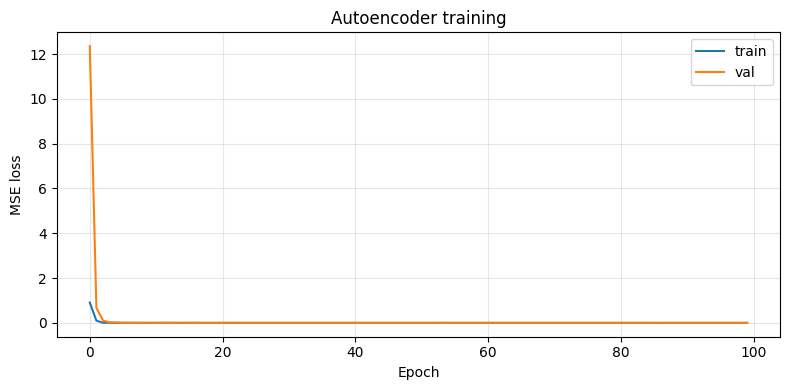

In [24]:
ae.compile(optimizer='adam', loss='mean_squared_error', jit_compile=False)

AE_EPOCHS=100

ae_early_stop = EarlyStopping(
    monitor='val_loss', patience=20, min_delta=1e-7,
    mode='min', verbose=1, restore_best_weights=True,
)

history_ae = ae.fit(
    [noisy_train_ae, pred_train_ae], clean_train_ae,
    validation_data=([noisy_val_ae, pred_val_ae], clean_val_ae),
    epochs=AE_BATCH_SIZE if False else AE_EPOCHS,      # keep AE_EPOCHS explicit
    batch_size=AE_BATCH_SIZE,
    callbacks=[ae_early_stop],
    verbose=2,
)

# Training curve
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_ae.history['loss'],     label='train')
ax.plot(history_ae.history['val_loss'], label='val')
ax.set(xlabel='Epoch', ylabel='MSE loss', title='Autoencoder training')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Genera reconstrucciones para algunas senales de prueba, las devuelve a sus unidades originales y las grafica en tres columnas: la contaminada, la reconstruida y la limpia verdadera. Despues calcula sobre todo el conjunto de prueba dos metricas, el error cuadratico medio (RMSE) y la relacion senal a ruido (SNR), comparando la senal contaminada y la reconstruida contra la limpia, para medir cuanto mejoro.

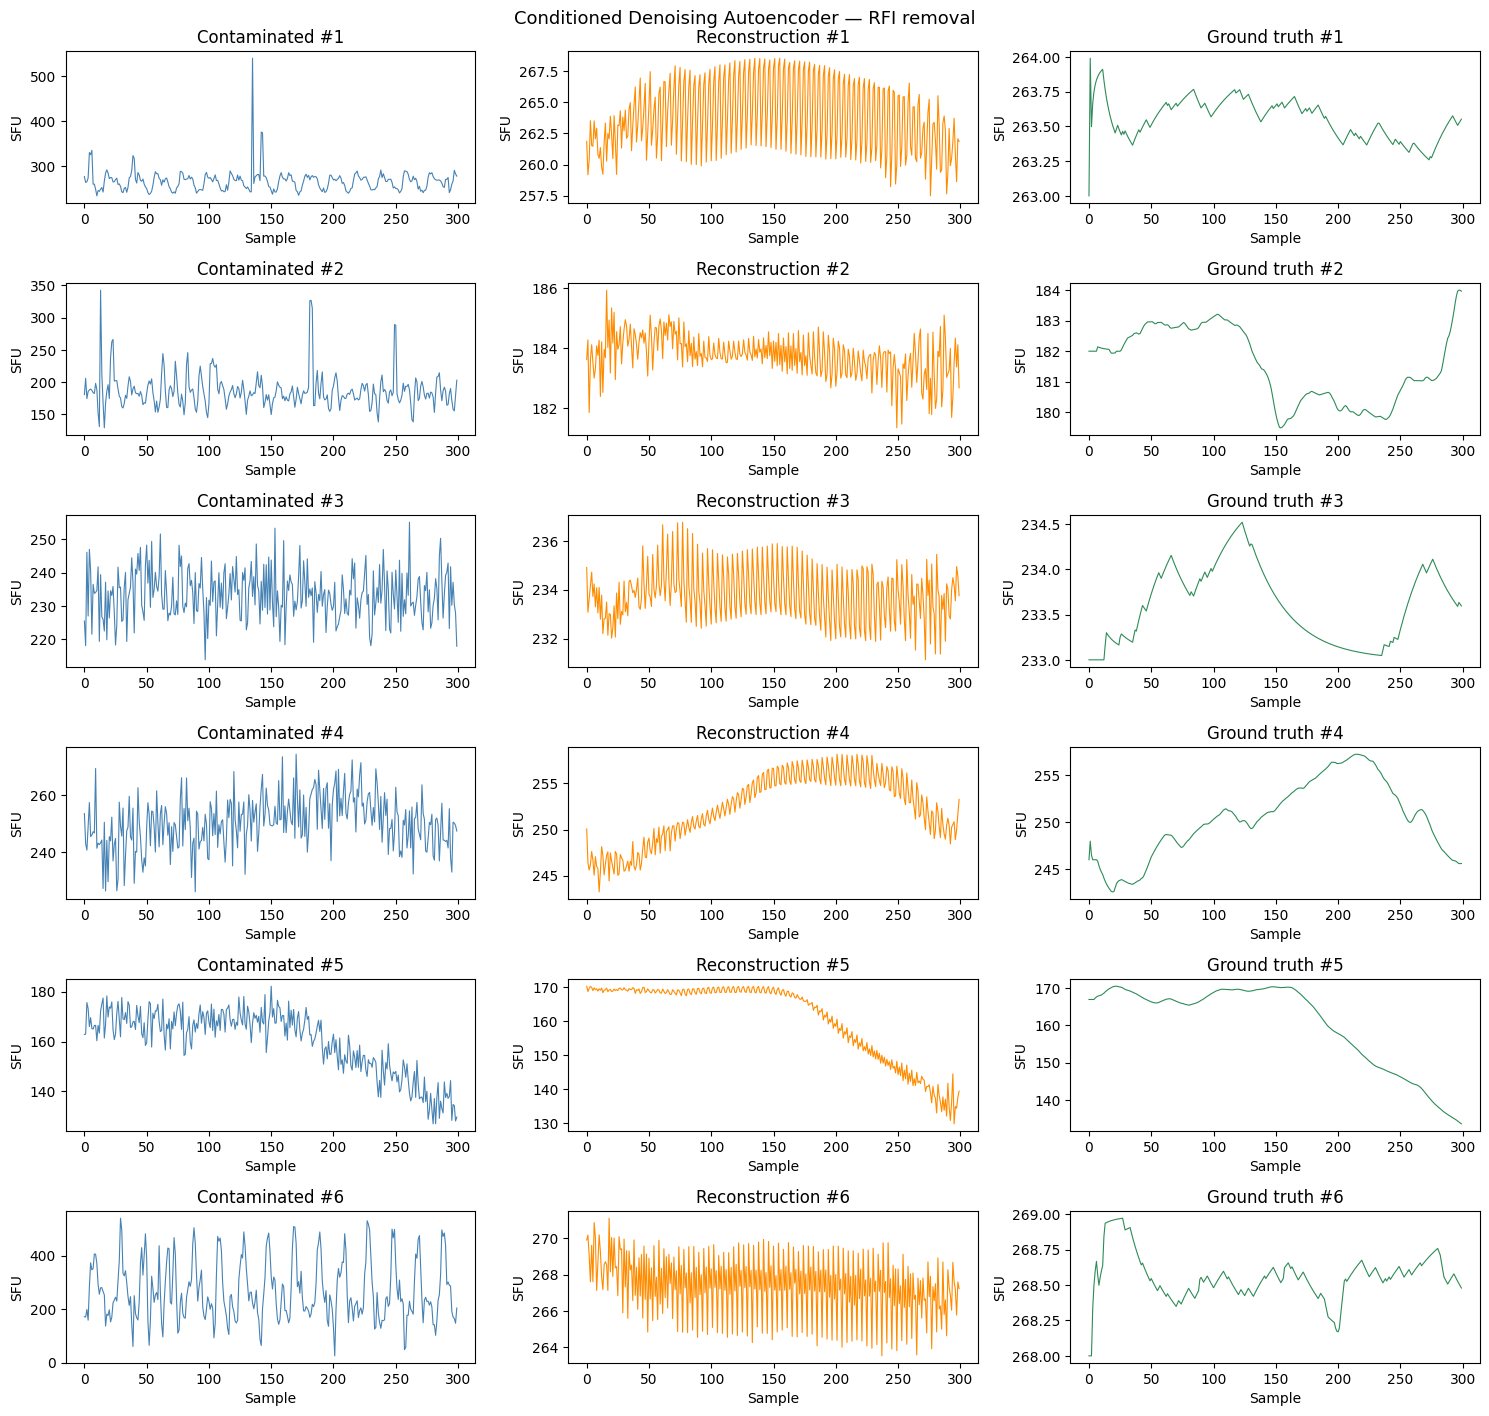

RMSE on test set:
  contaminated vs clean : 219.974 SFU
  reconstructed vs clean: 47.610 SFU  (+78% improvement)

SNR on test set:
  contaminated : +8.0 dB
  reconstructed: +21.2 dB  (+13.3 dB gain)


In [25]:
NUM_RECONSTRUCTIONS = 6

recon_norm = ae.predict(
    [noisy_test_ae[:NUM_RECONSTRUCTIONS], pred_test_ae[:NUM_RECONSTRUCTIONS]],
    verbose=0,
).squeeze()                                                          # (n, 300)

# Denormalize back to original units (SFU)
noisy_orig = peak_denormalize(noisy_test_ae[:NUM_RECONSTRUCTIONS].squeeze(),
                               peaks_test[:NUM_RECONSTRUCTIONS])
recon_orig = peak_denormalize(recon_norm, peaks_test[:NUM_RECONSTRUCTIONS])
clean_orig = peak_denormalize(clean_test_ae[:NUM_RECONSTRUCTIONS].squeeze(),
                               peaks_test[:NUM_RECONSTRUCTIONS])


def plot_ae_results(noisy, recon, clean, n=NUM_RECONSTRUCTIONS):
    fig, axes = plt.subplots(n, 3, figsize=(15, 2.4*n))
    fig.suptitle('Conditioned Denoising Autoencoder — RFI removal',
                  fontsize=13)
    for i in range(n):
        axes[i, 0].plot(noisy[i], color='steelblue',  lw=0.8)
        axes[i, 0].set_title(f'Contaminated #{i+1}')
        axes[i, 1].plot(recon[i], color='darkorange', lw=0.8)
        axes[i, 1].set_title(f'Reconstruction #{i+1}')
        axes[i, 2].plot(clean[i], color='seagreen',   lw=0.8)
        axes[i, 2].set_title(f'Ground truth #{i+1}')
    for ax in axes.flat:
        ax.set_xlabel('Sample'); ax.set_ylabel('SFU')
    plt.tight_layout()
    plt.show()


plot_ae_results(noisy_orig, recon_orig, clean_orig)

# Quantitative metrics on the full test set
recon_test_norm = ae.predict([noisy_test_ae, pred_test_ae],
                              verbose=0).squeeze()
recon_test = peak_denormalize(recon_test_norm, peaks_test)
clean_test_arr = ds['clean'][i_test]                  # original SFU
noisy_test_arr = ds['contaminated'][i_test]

def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))
def snr_db(clean, noise):
    return 10*np.log10(np.mean(clean**2) / max(np.mean(noise**2), 1e-30))

rmse_noisy = rmse(noisy_test_arr, clean_test_arr)
rmse_recon = rmse(recon_test,     clean_test_arr)
snr_noisy  = snr_db(clean_test_arr, noisy_test_arr - clean_test_arr)
snr_recon  = snr_db(clean_test_arr, recon_test     - clean_test_arr)

print(f"RMSE on test set:")
print(f"  contaminated vs clean : {rmse_noisy:.3f} SFU")
print(f"  reconstructed vs clean: {rmse_recon:.3f} SFU  "
      f"({(1 - rmse_recon/rmse_noisy)*100:+.0f}% improvement)")
print(f"\nSNR on test set:")
print(f"  contaminated : {snr_noisy:+.1f} dB")
print(f"  reconstructed: {snr_recon:+.1f} dB  "
      f"({snr_recon - snr_noisy:+.1f} dB gain)")

Guarda el autoencoder entrenado en un archivo.

In [ ]:
#ae.save("Autoencoder.keras")

Define un filtro LMS normalizado en una dimension, otro metodo clasico de filtrado adaptativo. Ajusta sus coeficientes muestra a muestra para predecir la senal y reducir el error. Devuelve la senal filtrada, el error y la evolucion de los pesos. Aqui se define como alternativa de comparacion.

In [ ]:
def lms_filter_1d(signal, mu=0.01, filter_order=4, epsilon=1e-8):
    """
    Stable 1D Normalized LMS filter for signal denoising.

    Parameters
    ----------
    signal : array-like
        Input noisy signal.

    mu : float
        Adaptation step size (recommended: 0.001 to 0.1)

    filter_order : int
        Number of adaptive coefficients.

    epsilon : float
        Small constant to avoid division by zero.

    Returns
    -------
    filtered_signal : ndarray
        Filtered output signal.

    residuals : ndarray
        Error signal.

    weights_history : ndarray
        Evolution of adaptive weights.
    """

    signal = np.asarray(signal, dtype=np.float64)

    n = len(signal)

    filtered_signal = np.zeros(n)
    residuals = np.zeros(n)

    # Adaptive weights
    w = np.zeros(filter_order)

    weights_history = np.zeros((n, filter_order))

    for k in range(filter_order, n):

        # Input vector
        x = signal[k-filter_order:k][::-1]

        # Filter output
        y = np.dot(w, x)

        # Desired signal
        d = signal[k]

        # Error
        e = d - y

        # Input power normalization
        norm_factor = np.dot(x, x) + epsilon

        # Normalized LMS update
        w = w + (mu / norm_factor) * e * x

        # Store results
        filtered_signal[k] = y
        residuals[k] = e
        weights_history[k] = w

    # Fill initial samples
    filtered_signal[:filter_order] = signal[:filter_order]

    return filtered_signal, residuals, weights_history

Aplica un filtro de Kalman a la salida del autoencoder, ventana por ventana, como un suavizado posterior.

In [26]:
samples= len(recon_test)
points=300
t = np.linspace(0, 300, points)
filtered_signal= np.empty((samples, points))
filtered_origin= np.empty((samples, points))
for i in range(len(recon_test)):
    filtered_signal[i], residuals, K_values = kalman_filter_1d(recon_test[i], Q=1e-2, R=1e-4, x0=None, P0=1.0)
    #filtered_origin[i], residuals, K_values = lms_filter_1d(clean_test_arr[i], mu=0.01, filter_order=4)
   # filtered_signal[i], residuals, K_values = lms_filter_1d(recon_test[i], mu=0.01, filter_order=4)

Vuelve a calcular el RMSE y la SNR, ahora comparando la senal del autoencoder ya suavizada con Kalman contra la limpia. Sirve para ver el efecto de ese filtrado posterior.

In [27]:





filtered_origin=clean_test_arr



rmse_noisy = rmse(noisy_test_arr, filtered_origin)
rmse_recon = rmse(filtered_signal,     filtered_origin)
snr_noisy  = snr_db(filtered_origin, noisy_test_arr - filtered_origin)
snr_recon  = snr_db(filtered_origin, filtered_signal     - filtered_origin)




print(f"RMSE on test set:")
print(f"  contaminated vs clean : {rmse_noisy:.3f} SFU")
print(f"  reconstructed vs clean: {rmse_recon:.3f} SFU  "
      f"({(1 - rmse_recon/rmse_noisy)*100:+.0f}% improvement)")
print(f"\nSNR on test set:")
print(f"  contaminated : {snr_noisy:+.1f} dB")
print(f"  reconstructed: {snr_recon:+.1f} dB  "
      f"({snr_recon - snr_noisy:+.1f} dB gain)")

RMSE on test set:
  contaminated vs clean : 219.974 SFU
  reconstructed vs clean: 47.561 SFU  (+78% improvement)

SNR on test set:
  contaminated : +8.0 dB
  reconstructed: +21.3 dB  (+13.3 dB gain)


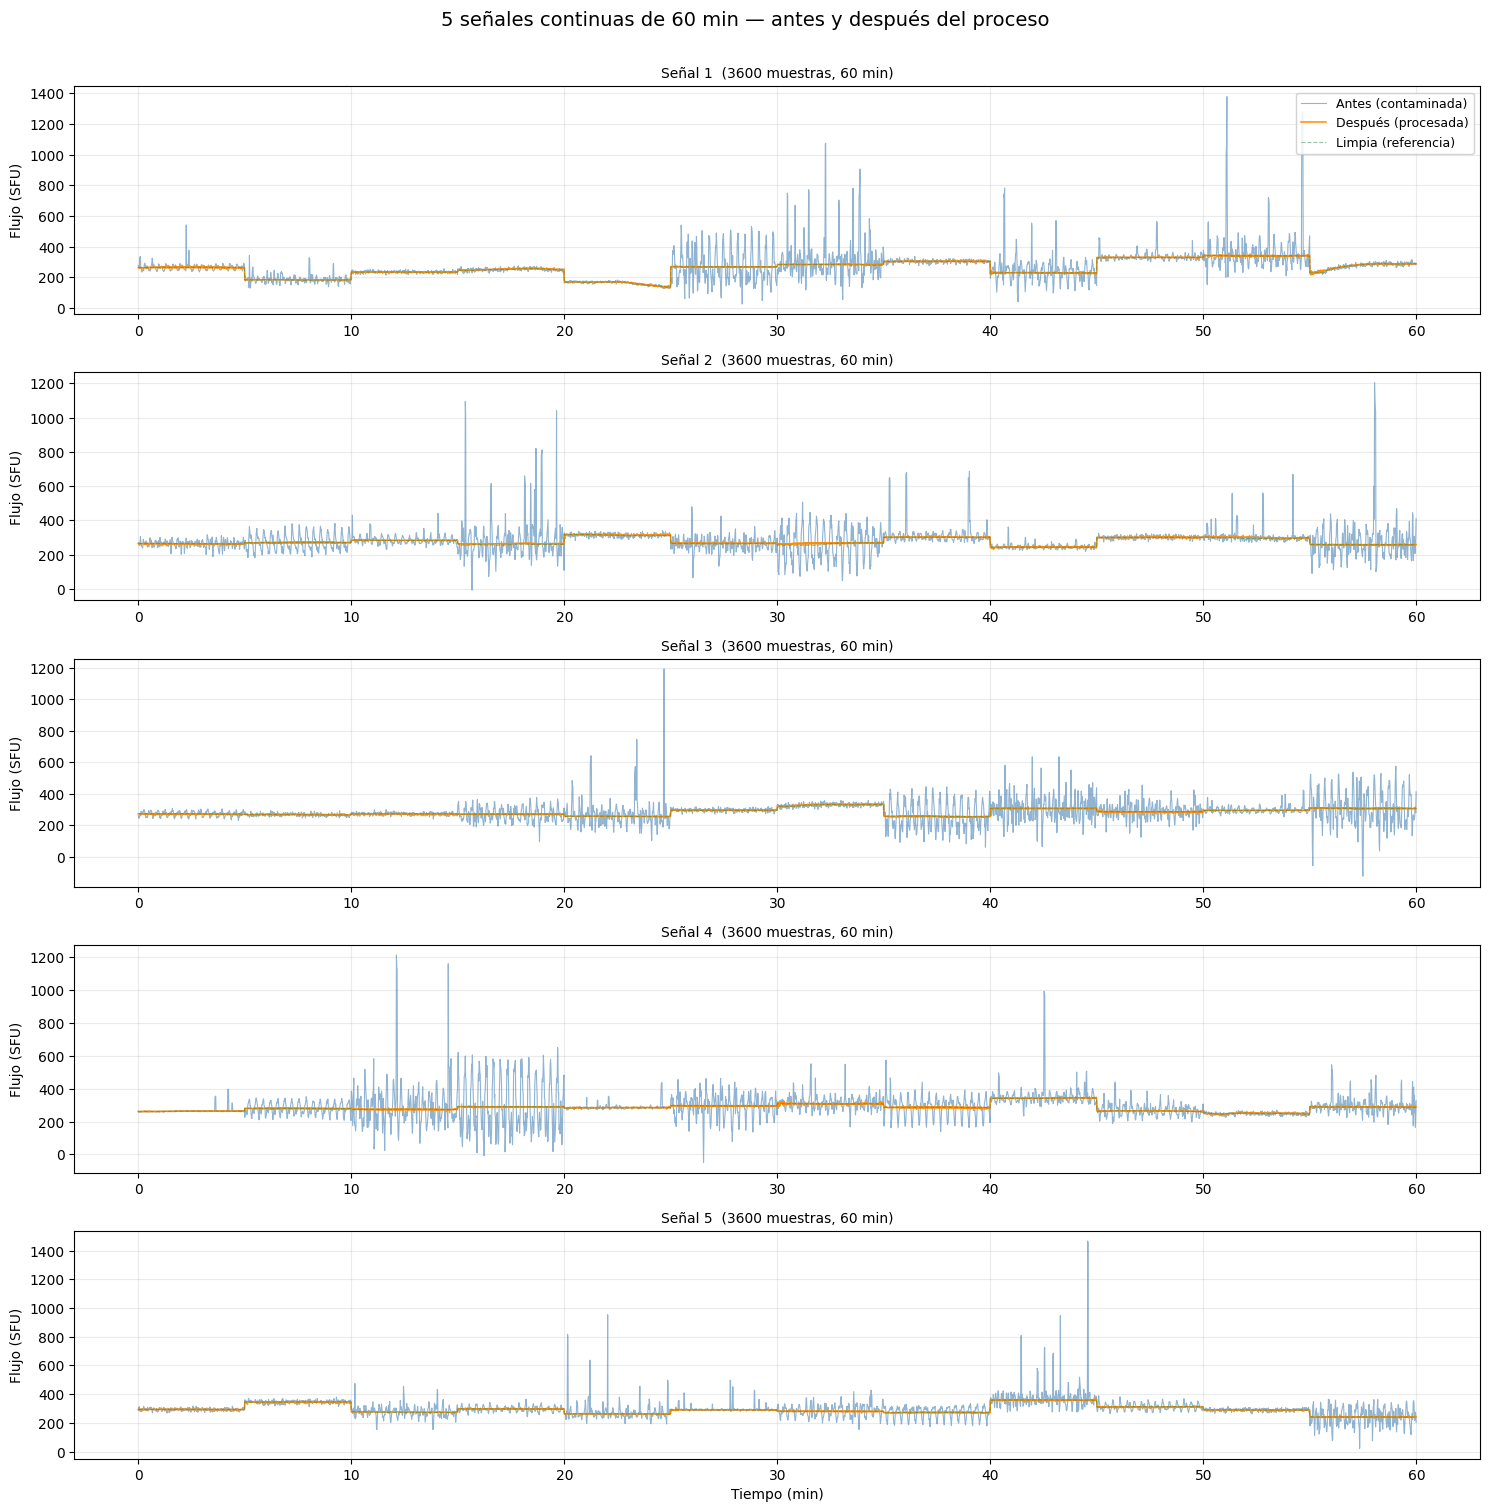

In [28]:
# ── Visualización: 5 señales continuas de 1 hora, antes y después del proceso ──
#
# "Antes"  = señal contaminada (noisy_test_arr)
# "Después" = salida final del proceso = reconstrucción del autoencoder
#            suavizada con Kalman (filtered_signal).
#            Si querés solo el autoencoder, cambiá `after_src = filtered_signal`
#            por `after_src = recon_test`.

before_src = noisy_test_arr        # (N_test, 300) contaminada, en SFU
after_src  = filtered_signal       # (N_test, 300) procesada (AE + Kalman)
clean_src  = clean_test_arr        # (N_test, 300) limpia de referencia

WIN          = N_FULL                                   # 300 muestras por ventana
DUR_MIN      = 60                                       # duración mínima por señal
WINS_PER_SIG = int(np.ceil(DUR_MIN * 60 * SAMPLE_RATE / WIN))   # = 12 ventanas → 1 h
N_SHOW       = 5                                         # cantidad de señales a mostrar

need = N_SHOW * WINS_PER_SIG
assert len(after_src) >= need, (
    f"Se necesitan {need} ventanas y solo hay {len(after_src)}."
)

fig, axes = plt.subplots(N_SHOW, 1, figsize=(15, 3.0 * N_SHOW))
fig.suptitle(
    f"{N_SHOW} señales continuas de {DUR_MIN} min — antes y después del proceso",
    fontsize=14, y=1.005,
)

for k in range(N_SHOW):
    r0 = k * WINS_PER_SIG
    sel = slice(r0, r0 + WINS_PER_SIG)

    before = before_src[sel].ravel()
    after  = after_src[sel].ravel()
    clean  = clean_src[sel].ravel()
    t_min  = np.arange(len(before)) / SAMPLE_RATE / 60.0   # tiempo en minutos

    ax = axes[k]
    ax.plot(t_min, before, lw=0.8, color="steelblue", alpha=0.6, label="Antes (contaminada)")
    ax.plot(t_min, after,  lw=1.1, color="darkorange",            label="Después (procesada)")
    ax.plot(t_min, clean,  lw=0.8, color="seagreen", alpha=0.5, ls="--", label="Limpia (referencia)")
    ax.set_ylabel("Flujo (SFU)")
    ax.set_title(f"Señal {k+1}  ({len(before)} muestras, {len(before)/60:.0f} min)", fontsize=10)
    ax.grid(alpha=0.25)
    if k == 0:
        ax.legend(fontsize=9, loc="upper right", framealpha=0.85)

axes[-1].set_xlabel("Tiempo (min)")
plt.tight_layout()
plt.show()

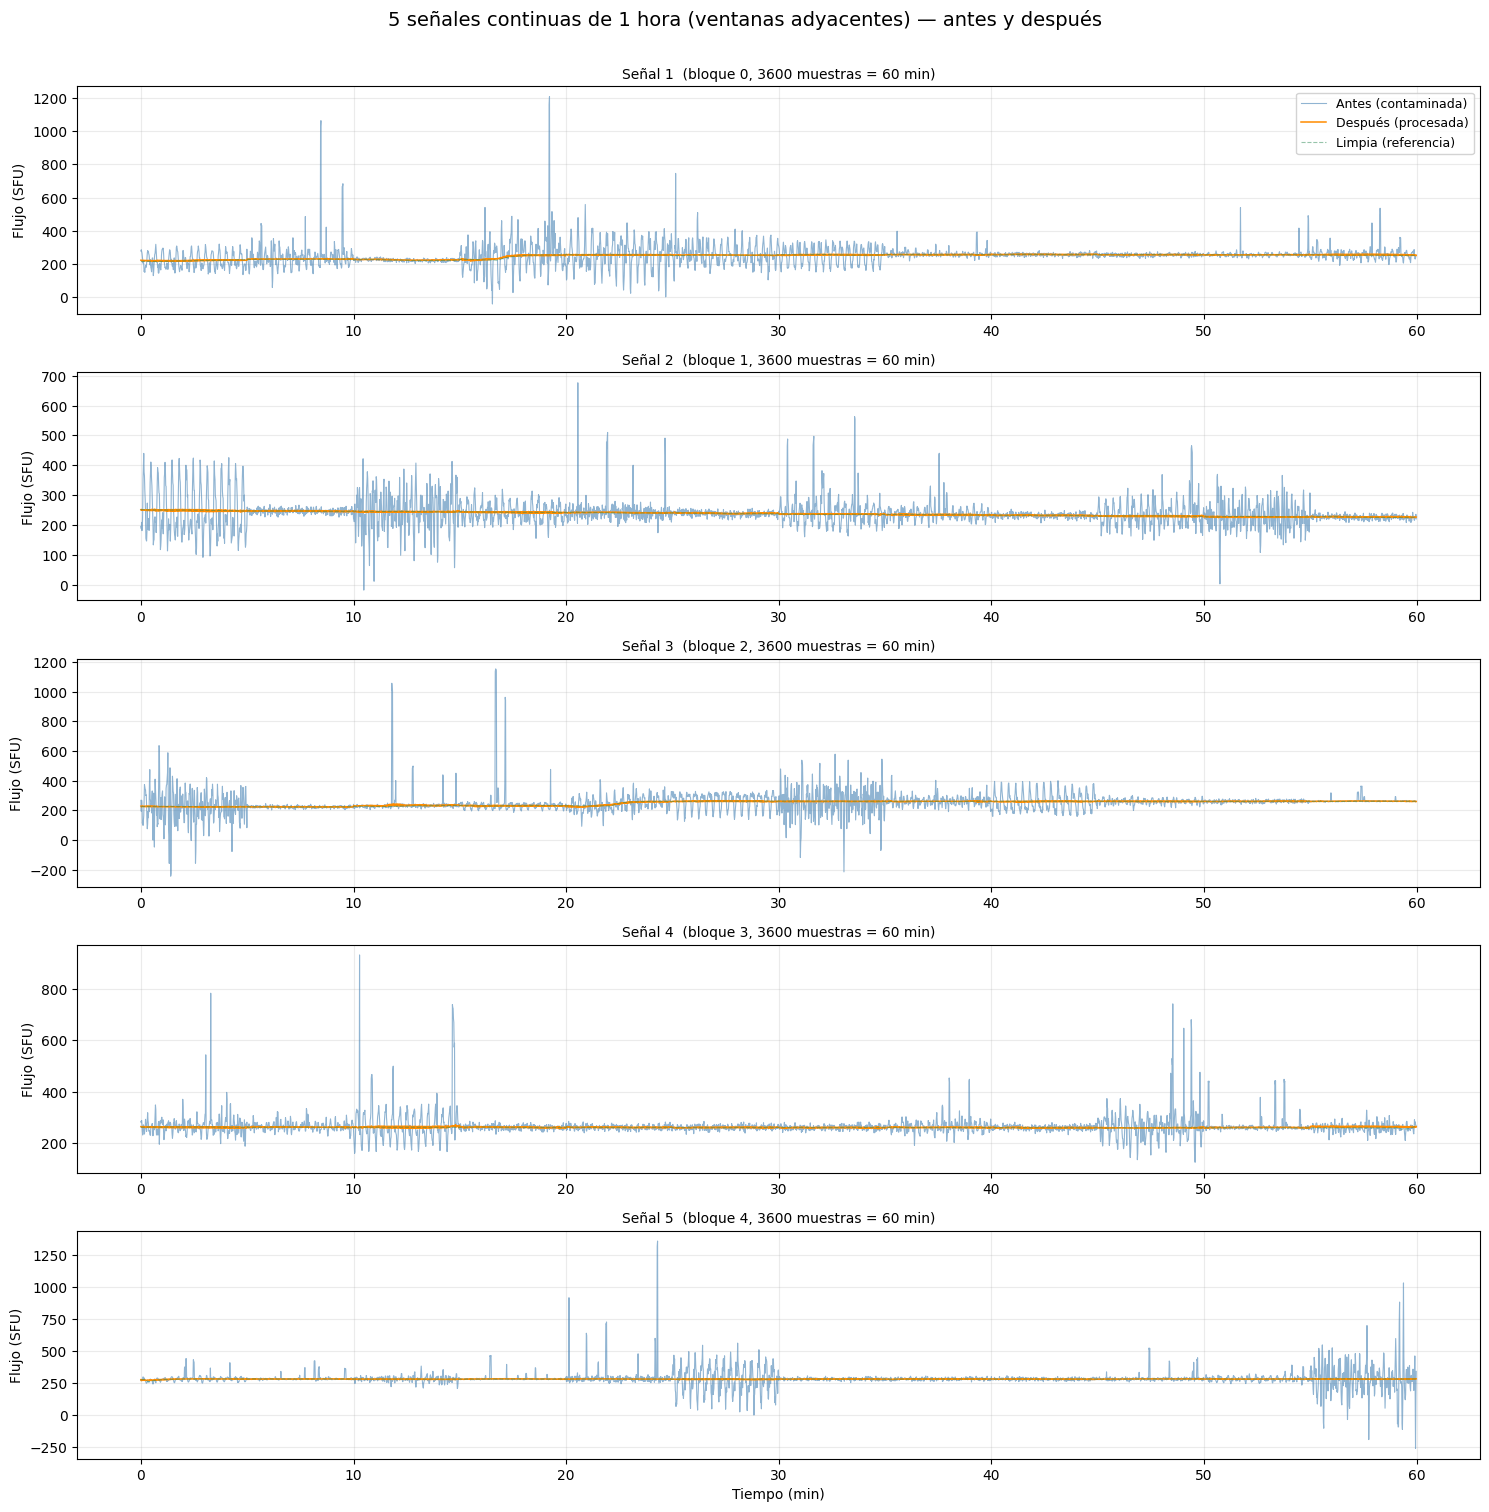

In [29]:
# ── Visualización: 5 señales continuas de 1 hora, temporalmente adyacentes ──
#
# Se toman ventanas CONSECUTIVAS directamente de `ds` (que conserva el orden de
# carga, shuffle=False), no del conjunto de prueba (que está permutado). Cada
# señal son 12 ventanas seguidas de 300 muestras = 3600 s = 1 hora de datos
# adyacentes. Se procesan en el momento con el clasificador y el autoencoder ya
# entrenados, y se grafica antes (contaminada) contra después (procesada).

import keras

# Modelos ya entrenados (usa los de memoria; si no están, los carga del disco)
try:
    m1d, ae
except NameError:
    m1d = keras.saving.load_model("Classifier.keras")
    ae  = keras.saving.load_model("Autoencoder.keras")

WIN          = N_FULL                                     # 300 muestras por ventana
WINS_PER_SIG = int(np.ceil(60 * 60 * SAMPLE_RATE / WIN))  # 12 ventanas → 1 hora
N_SHOW       = 5                                          # señales a mostrar
START_BLOCK  = 0                                          # cambiar para ver otra parte
KALMAN_Q, KALMAN_R = 1e-2, 1e-4                           # mismos del post-filtro

need = (START_BLOCK + N_SHOW) * WINS_PER_SIG
assert len(ds['contaminated']) >= need, \
    f"Se necesitan {need} ventanas y hay {len(ds['contaminated'])}."

# Selección de ventanas consecutivas (adyacentes en el tiempo)
i0  = START_BLOCK * WINS_PER_SIG
sel = slice(i0, i0 + N_SHOW * WINS_PER_SIG)
clean_sel = ds['clean'][sel]
noisy_sel = ds['contaminated'][sel]

# 1) Predicciones del clasificador (usa los primeros 60 de cada ventana)
sliced = slice_for_classifier(noisy_sel)
preds  = m1d.predict((prepare_1d(sliced), batch_scalograms(sliced)), verbose=0)

# 2) Normalización por pico (mismo pico para limpia y contaminada)
clean_n, noisy_n, peaks = paired_peak_normalize(clean_sel, noisy_sel)

# 3) Reconstrucción del autoencoder y vuelta a unidades originales (SFU)
recon_norm = ae.predict([noisy_n.reshape(-1, N_FULL, 1), preds], verbose=0).squeeze()
recon = peak_denormalize(recon_norm, peaks)

# 4) Post-filtro de Kalman, ventana por ventana (igual que en el proceso)
processed = np.empty_like(recon)
for j in range(len(recon)):
    processed[j], _, _ = kalman_filter_1d(recon[j], Q=KALMAN_Q, R=KALMAN_R)

# Para ver solo la salida del autoencoder sin Kalman, usar:  processed = recon

# 5) Graficar: cada señal es un bloque de ventanas consecutivas concatenadas
fig, axes = plt.subplots(N_SHOW, 1, figsize=(15, 3.0 * N_SHOW))
fig.suptitle(f"{N_SHOW} señales continuas de 1 hora (ventanas adyacentes) — antes y después",
             fontsize=14, y=1.005)

for k in range(N_SHOW):
    s = slice(k * WINS_PER_SIG, (k + 1) * WINS_PER_SIG)
    before = noisy_sel[s].ravel()
    after  = processed[s].ravel()
    clean  = clean_sel[s].ravel()
    t_min  = np.arange(len(before)) / SAMPLE_RATE / 60.0

    ax = axes[k]
    ax.plot(t_min, before, lw=0.8, color="steelblue", alpha=0.6, label="Antes (contaminada)")
    ax.plot(t_min, after,  lw=1.1, color="darkorange",            label="Después (procesada)")
    ax.plot(t_min, clean,  lw=0.8, color="seagreen", alpha=0.5, ls="--", label="Limpia (referencia)")
    ax.set_ylabel("Flujo (SFU)")
    ax.set_title(f"Señal {k+1}  (bloque {START_BLOCK + k}, {len(before)} muestras = {len(before)/60:.0f} min)",
                 fontsize=10)
    ax.grid(alpha=0.25)
    if k == 0:
        ax.legend(fontsize=9, loc="upper right", framealpha=0.85)

axes[-1].set_xlabel("Tiempo (min)")
plt.tight_layout()
plt.show()

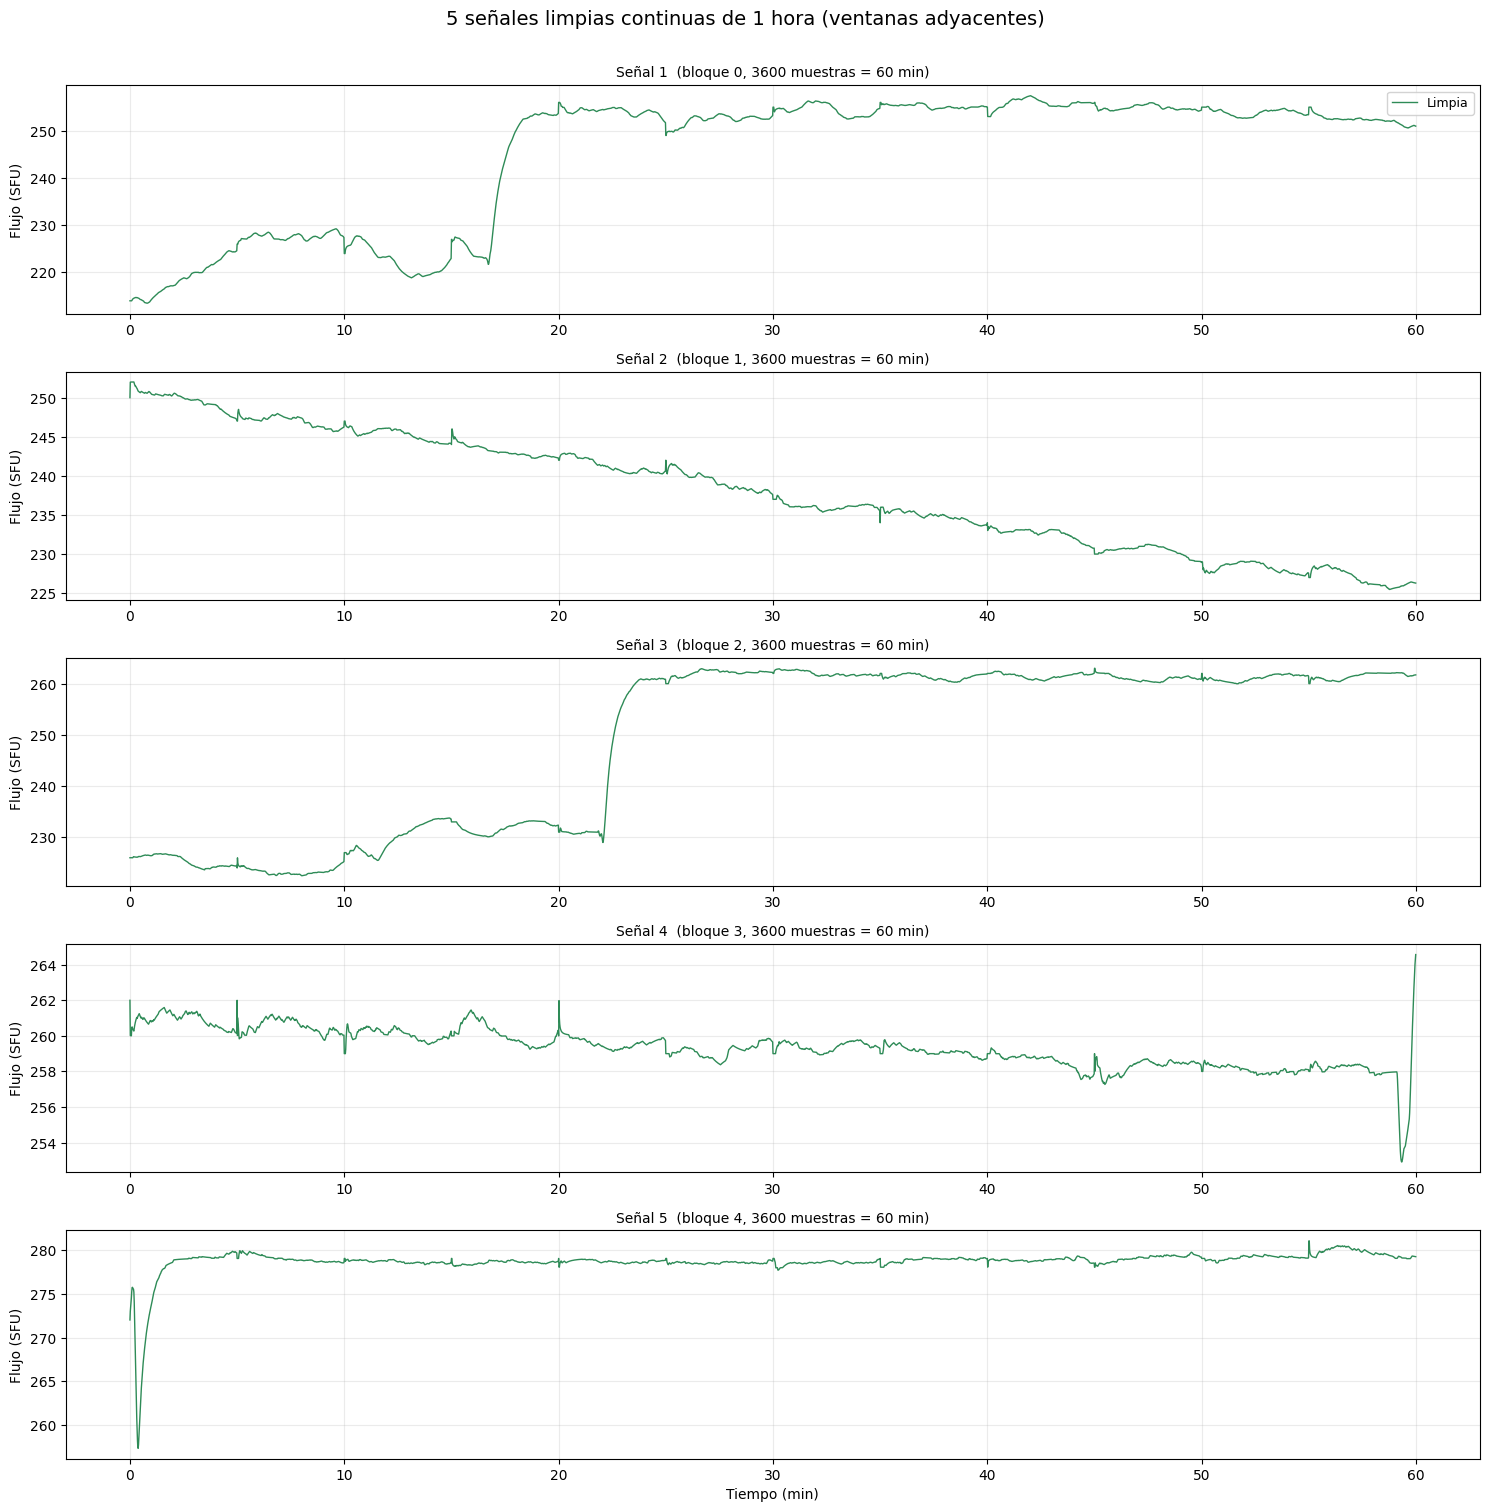

In [30]:
# ── Visualización: 5 señales limpias continuas de 1 hora (ventanas adyacentes) ──

WIN          = N_FULL                                     # 300 muestras por ventana
WINS_PER_SIG = int(np.ceil(60 * 60 * SAMPLE_RATE / WIN))  # 12 ventanas → 1 hora
N_SHOW       = 5                                          # señales a mostrar
START_BLOCK  = 0                                          # cambiar para ver otra parte

need = (START_BLOCK + N_SHOW) * WINS_PER_SIG
assert len(ds['clean']) >= need, \
    f"Se necesitan {need} ventanas y hay {len(ds['clean'])}."

i0  = START_BLOCK * WINS_PER_SIG
sel = slice(i0, i0 + N_SHOW * WINS_PER_SIG)
clean_sel = ds['clean'][sel]

fig, axes = plt.subplots(N_SHOW, 1, figsize=(15, 3.0 * N_SHOW))
fig.suptitle(f"{N_SHOW} señales limpias continuas de 1 hora (ventanas adyacentes)",
             fontsize=14, y=1.005)

for k in range(N_SHOW):
    s = slice(k * WINS_PER_SIG, (k + 1) * WINS_PER_SIG)
    clean = clean_sel[s].ravel()
    t_min = np.arange(len(clean)) / SAMPLE_RATE / 60.0

    ax = axes[k]
    ax.plot(t_min, clean, lw=1.0, color="seagreen", label="Limpia")
    ax.set_ylabel("Flujo (SFU)")
    ax.set_title(f"Señal {k+1}  (bloque {START_BLOCK + k}, {len(clean)} muestras = {len(clean)/60:.0f} min)",
                 fontsize=10)
    ax.grid(alpha=0.25)
    if k == 0:
        ax.legend(fontsize=9, loc="upper right", framealpha=0.85)

axes[-1].set_xlabel("Tiempo (min)")
plt.tight_layout()
plt.show()

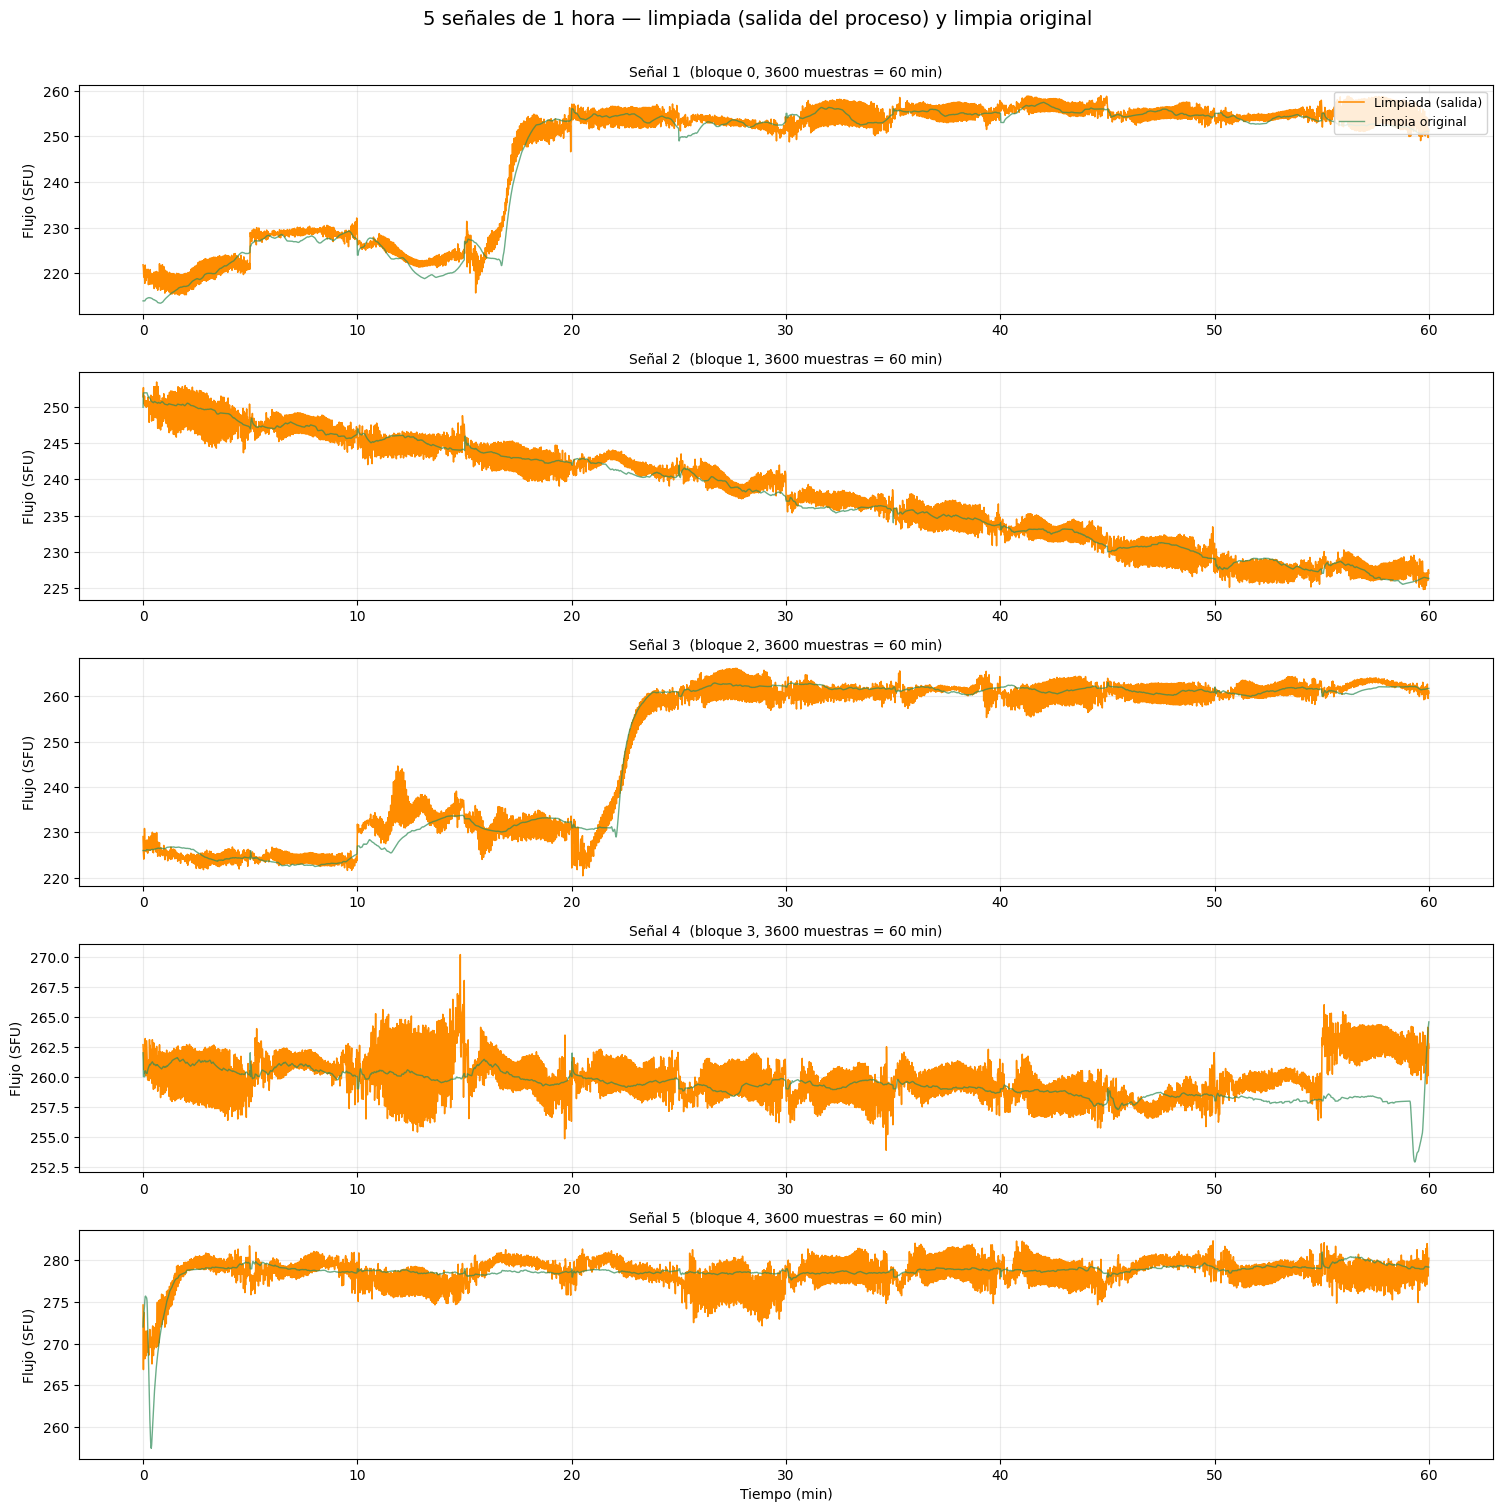

In [ ]:
# ── Visualización: señal limpiada (salida del proceso) vs. señal limpia original ──
#
# "Limpiada" = reconstrucción del autoencoder + post-filtro de Kalman.
# Se procesan ventanas CONSECUTIVAS de `ds` (orden de carga) para que cada
# señal de 1 hora sea temporalmente adyacente.

import keras
try:
    m1d, ae
except NameError:
    m1d = keras.saving.load_model("Classifier.keras")
    ae  = keras.saving.load_model("Autoencoder.keras")

WIN          = N_FULL                                     # 300 muestras por ventana
WINS_PER_SIG = int(np.ceil(60 * 60 * SAMPLE_RATE / WIN))  # 12 ventanas → 1 hora
N_SHOW       = 5
START_BLOCK  = 0                                          # cambiar para ver otra parte
KALMAN_Q, KALMAN_R = 1e-2, 1e-4

need = (START_BLOCK + N_SHOW) * WINS_PER_SIG
assert len(ds['clean']) >= need, \
    f"Se necesitan {need} ventanas y hay {len(ds['clean'])}."

i0  = START_BLOCK * WINS_PER_SIG
sel = slice(i0, i0 + N_SHOW * WINS_PER_SIG)
clean_sel = ds['clean'][sel]
noisy_sel = ds['contaminated'][sel]

# 1) Predicciones del clasificador (primeros 60 de cada ventana)
sliced = slice_for_classifier(noisy_sel)
preds  = m1d.predict((prepare_1d(sliced), batch_scalograms(sliced)), verbose=0)

# 2) Normalización por pico + reconstrucción del autoencoder
clean_n, noisy_n, peaks = paired_peak_normalize(clean_sel, noisy_sel)
recon_norm = ae.predict([noisy_n.reshape(-1, N_FULL, 1), preds], verbose=0).squeeze()
recon = peak_denormalize(recon_norm, peaks)

# 3) Post-filtro de Kalman, ventana por ventana
cleaned = np.empty_like(recon)
for j in range(len(recon)):
    cleaned[j], _, _ = kalman_filter_1d(recon[j], Q=KALMAN_Q, R=KALMAN_R)
# Para ver solo el autoencoder sin Kalman, usar:  cleaned = recon

# 4) Graficar limpiada vs. limpia original
fig, axes = plt.subplots(N_SHOW, 1, figsize=(15, 3.0 * N_SHOW))
fig.suptitle(f"{N_SHOW} señales de 1 hora — limpiada (salida del proceso) y limpia original",
             fontsize=14, y=1.005)

for k in range(N_SHOW):
    s = slice(k * WINS_PER_SIG, (k + 1) * WINS_PER_SIG)
    out_clean = cleaned[s].ravel()
    orig_clean = clean_sel[s].ravel()
    out_clean, _, _ = kalman_filter_1d(out_clean, Q=1e-2, R=1e-4, x0=None, P0=1.0)

    t_min = np.arange(len(out_clean)) / SAMPLE_RATE / 60.0

    ax = axes[k]
    ax.plot(t_min, out_clean,  lw=1.1, color="darkorange", label="Limpiada (salida)")
    ax.plot(t_min, orig_clean, lw=1.0, color="seagreen", alpha=0.7, label="Limpia original")
    ax.set_ylabel("Flujo (SFU)")
    ax.set_title(f"Señal {k+1}  (bloque {START_BLOCK + k}, {len(out_clean)} muestras = {len(out_clean)/60:.0f} min)",
                 fontsize=10)
    ax.grid(alpha=0.25)
    if k == 0:
        ax.legend(fontsize=9, loc="upper right", framealpha=0.85)

axes[-1].set_xlabel("Tiempo (min)")
plt.tight_layout()
plt.show()